# Разделительная кластеризация клиентов банка

Практическая работа: собственные **k-Means (Lloyd)** и **k-Medoids (полный PAM SWAP)**,
850 клиентов, шесть количественных признаков. Все данные встроены в ноутбук.

**Запуск в Google Colab:** загрузите этот `.ipynb`, выберите **Среда выполнения →
Выполнить все**. GPU не требуется. Результаты и CSV появятся в `partition_clustering/results`,
в конце можно скачать ZIP. При запуске на другом компьютере установите
`numpy pandas matplotlib scipy scikit-learn`. Основная сетка выполняет 210 запусков;
время зависит от CPU.

**Связь с лекциями.** В «04 Кластеризация» используются центроиды и SSE (слайды 9–14),
перезапуски (27), медоиды и PAM (28–30), метод локтя (64), силуэт (67–68).
На слайде 29 у PAM стоят квадраты расстояний: в основной сетке использована эта же
цель. Параметр `medoid_power=1` включает отдельный вариант с обычными расстояниями.
Лекции «03 Классификация-2» и «02 Шаблоны» посвящены другим задачам: здесь нет
целевой метки для обучения и не ищутся частые наборы. Их алгоритмы в эту работу
не подмешиваются.

## Параметры и данные

`K` и `NOISE_FRACTION` управляют отдельным демонстрационным запуском.
Основная сетка всегда охватывает k=3..9 и 0%, 1%, 3%, 5%, 10% шума.
Чтобы использовать другой CSV, укажите `DATA_PATH` и `FEATURE_COLUMNS`.
Загрузка в Colab доступна через панель файлов слева. Для customers оставьте значения ниже.

In [1]:
from pathlib import Path
import os, io, base64, hashlib, json, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd() / 'partition_clustering'
(ROOT / 'data').mkdir(parents=True, exist_ok=True)
(ROOT / 'results').mkdir(parents=True, exist_ok=True)
K = 4
NOISE_FRACTION = 0.03
ALGORITHM = 'kmeans'  # 'kmeans' или 'kmedoids'
N_INIT = 5
DATA_PATH = ''  # пустая строка использует встроенный customers.csv
FEATURE_COLUMNS = ['Age', 'YearsEmployed', 'Income', 'CardDebt', 'OtherDebt', 'DebtIncomeRatio']

In [2]:
# Точная копия предоставленного customers.csv; проверяется SHA-256.
EMBEDDED_CSV = '...'
raw_bytes = base64.b64decode(EMBEDDED_CSV)
assert hashlib.sha256(raw_bytes).hexdigest() == 'da159195f03edb9ec892a044843c8b37c4d341f6fbb69fe4f91fb71f0d486dcc'
if DATA_PATH:
    frame = pd.read_csv(DATA_PATH)
else:
    (ROOT / 'data/customers.csv').write_bytes(raw_bytes)
    frame = pd.read_csv(io.BytesIO(raw_bytes))
print('Объектов:', len(frame), 'Столбцов:', len(frame.columns))
display(frame.head())
display(frame.isna().sum().rename('Пропуски').to_frame())

Объектов: 850 Столбцов: 10


,Row,CustomerId,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,Defaulted,DebtIncomeRatio
0,0,1,41,2,6,19,0.124,1.073,0.0,6.3
1,1,2,47,1,26,100,4.582,8.218,0.0,12.8
2,2,3,33,2,10,57,6.111,5.802,1.0,20.9
3,3,4,29,2,4,19,0.681,0.516,0.0,6.3
4,4,5,47,1,31,253,9.308,8.908,0.0,7.2


,Пропуски
Row,0
CustomerId,0
Age,0
Education,0
YearsEmployed,0
Income,0
CardDebt,0
OtherDebt,0
Defaulted,150
DebtIncomeRatio,0


## Подготовка и выбор признаков

Исключены `Row`, `CustomerId` (порядок и идентификатор), `Education` (категориальный код)
и `Defaulted` (бинарный исход, в котором 150 пропусков). Метки банкротства не задают
кластеры. В шести выбранных признаках пропусков нет; все 850 клиентов сохранены.
Стаж и возраст рассматриваются как количественные величины. При произвольном CSV
пропуски числовых признаков заполняются медианами.

Стандартизация: $z_{ij}=(x_{ij}-\mu_j)/\sigma_j$, где $\sigma_j$ рассчитана с `ddof=0`.
Средние, масштабы и оси PCA оцениваются **один раз по исходным данным**. После
добавления шума они не переоцениваются, иначе шум менял бы саму шкалу сравнения.
Все расстояния и ошибки вычисляются в полном пространстве признаков.

`DebtIncomeRatio` связан с долгами и доходом, поэтому финансовая нагрузка получает
дополнительный вес. Это осознанная особенность выбранного признакового пространства.

## Реализация алгоритмов

Оба алгоритма назначают объект ближайшему представителю.
$SSE=\sum_{i=1}^{n}\|z_i-c_{a_i}\|_2^2$.

* **k-Means:** D²-инициализация, назначение точек, пересчет центроидов средними,
  повторение до неизменности меток. Пустые кластеры восстанавливаются.
* **k-Medoids:** представителями служат реальные строки. На каждом шаге проверяются
  все обмены «медоид — не-медоид»; принимается лучший строго улучшающий обмен.
  Остановка означает отсутствие улучшающего одиночного обмена. Это усиливает
  случайную проверку обмена из учебного псевдокода, сохраняя его целевую функцию.

Каждый запуск включает пять начальных конфигураций; выбирается минимальная цель.
Локальный минимум не считается доказательством глобального оптимума. Квадратичная
цель PAM усиливает вклад выбросов; универсальное превосходство в устойчивости
из нее не следует.

In [3]:
"""Разделительная кластеризация: собственные Lloyd k-Means и PAM k-Medoids.

Вход: числовая матрица X размера (n, d), k, доля шумных строк.
Выход: метки, представители, SSE, история оптимизации и таблица координат.
Квадратичная цель PAM соответствует слайду 29 лекции 04. power=1 включает
вариант с суммой обычных евклидовых расстояний. sklearn для обучения не нужен.
"""
from dataclasses import dataclass
from pathlib import Path
import argparse
import json
import numpy as np
import pandas as pd

FEATURES = ["Age", "YearsEmployed", "Income", "CardDebt", "OtherDebt", "DebtIncomeRatio"]


@dataclass
class Fit:
    """Результат: labels (n,), centers (k,d), SSE и значение целевой функции.

    medoid_indices: индексы строк X либо None; history: убывающая цель лучшего
    запуска; converged: достигнут ли критерий останова; iterations: число шагов.
    """
    labels: np.ndarray
    centers: np.ndarray
    sse: float
    objective: float
    history: list
    converged: bool
    iterations: int
    medoid_indices: np.ndarray | None = None


def validate(X, k):
    """Проверить конечную матрицу X и целое 1 <= k <= число уникальных строк."""
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or min(X.shape) == 0 or not np.isfinite(X).all():
        raise ValueError("X должна быть непустой конечной двумерной матрицей")
    if isinstance(k, bool) or int(k) != k or not 1 <= k <= len(np.unique(X, axis=0)):
        raise ValueError("k должно быть целым от 1 до числа уникальных объектов")
    return X, int(k)


def squared_distances(X, Y):
    """Вернуть матрицу (len(X),len(Y)) квадратов евклидовых расстояний."""
    # Прямое вычитание предотвращает потерю точности при больших координатах.
    return np.sum((X[:, None, :] - Y[None, :, :]) ** 2, axis=2)


def initialize(X, k, rng):
    """Выбрать k разных точек по схеме D²; вернуть их индексы (k,)."""
    chosen = [int(rng.integers(len(X)))]
    closest = squared_distances(X, X[chosen]).ravel()
    for _ in range(1, k):
        idx = int(rng.choice(len(X), p=closest / closest.sum()))
        chosen.append(idx)
        closest = np.minimum(closest, squared_distances(X, X[[idx]]).ravel())
    return np.asarray(chosen, dtype=int)


def kmeans(X, k, seed=2026, n_init=5, max_iter=300):
    """Lloyd k-Means с D²-инициализацией и выбором минимума SSE.

    X: (n,d); k: число кластеров; seed: воспроизводимое зерно; n_init: число
    независимых запусков; max_iter: предел итераций. Возвращает Fit. Пустой
    кластер получает наиболее удаленную точку из кластера с размером > 1.
    """
    X, k = validate(X, k)
    if n_init < 1 or max_iter < 1:
        raise ValueError("n_init и max_iter должны быть положительными")
    best = None
    rng = np.random.default_rng(seed)
    for _ in range(n_init):
        centers = X[initialize(X, k, rng)].copy()
        previous = None
        history = []
        converged = False
        for it in range(1, max_iter + 1):
            dist = squared_distances(X, centers)
            labels = dist.argmin(axis=1)
            counts = np.bincount(labels, minlength=k)
            for empty in np.flatnonzero(counts == 0):
                loss = dist[np.arange(len(X)), labels].copy()
                loss[counts[labels] <= 1] = -np.inf
                point = int(loss.argmax())
                counts[labels[point]] -= 1
                labels[point] = empty
                counts[empty] += 1
            centers = np.array([X[labels == j].mean(axis=0) for j in range(k)])
            loss = float(np.sum((X - centers[labels]) ** 2))
            history.append(loss)
            if previous is not None and np.array_equal(labels, previous):
                converged = True
                break
            previous = labels.copy()
        fit = Fit(labels, centers, loss, loss, history, converged, it)
        if best is None or fit.objective < best.objective:
            best = fit
    return best


def pam(X, k, seed=2026, n_init=5, max_iter=300, power=2, distance_matrix=None):
    """Полный PAM SWAP: на каждом шаге проверить все обмены медоид/не-медоид.

    X: (n,d); k: число медоидов; seed/n_init/max_iter: параметры запусков;
    power=2: сумма квадратов расстояний (лекция), power=1: сумма расстояний;
    distance_matrix: необязательная готовая матрица целевых расстояний (n,n).
    Возвращает Fit. Остановка только при отсутствии улучшающего обмена либо
    по max_iter. Это локальный минимум по одиночным обменам, не глобальный.
    """
    X, k = validate(X, k)
    if power not in (1, 2) or n_init < 1 or max_iter < 1:
        raise ValueError("power должен быть 1 или 2; n_init/max_iter > 0")
    D = squared_distances(X, X) if distance_matrix is None else np.asarray(distance_matrix)
    if distance_matrix is None and power == 1:
        D = np.sqrt(D)
    if D.shape != (len(X), len(X)) or not np.isfinite(D).all() or np.any(D < 0):
        raise ValueError("Некорректная матрица расстояний")
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        medoids = initialize(X, k, rng)
        history = []
        converged = False
        for it in range(1, max_iter + 1):
            dm = D[:, medoids]
            labels = dm.argmin(axis=1)
            d1 = dm[np.arange(len(X)), labels]
            d2 = np.partition(dm, 1, axis=1)[:, 1] if k > 1 else np.full(len(X), np.inf)
            cost = float(d1.sum())
            if not history:
                history.append(cost)
            # Общая выгода кандидата, если прежний ближайший медоид сохранен.
            base = (np.minimum(D, d1[:, None]) - d1[:, None]).sum(axis=0)
            delta = np.empty((k, len(X)))
            # Для объектов удаляемого кластера резервным становится второй медоид.
            for j in range(k):
                owned = labels == j
                delta[j] = base + (
                    np.minimum(D[owned], d2[owned, None])
                    - np.minimum(D[owned], d1[owned, None])
                ).sum(axis=0)
            delta[:, medoids] = np.inf
            position, candidate = np.unravel_index(np.argmin(delta), delta.shape)
            if delta[position, candidate] >= -1e-9:
                converged = True
                break
            medoids[position] = candidate
            history.append(float(D[:, medoids].min(axis=1).sum()))
        labels = D[:, medoids].argmin(axis=1)
        centers = X[medoids].copy()
        sse = float(np.sum((X - centers[labels]) ** 2))
        objective = float(D[np.arange(len(X)), medoids[labels]].sum())
        fit = Fit(labels, centers, sse, objective, history, converged, it, medoids.copy())
        if best is None or fit.objective < best.objective:
            best = fit
    return best


def prepare_data(frame, features=None):
    """Выбрать features из DataFrame, заполнить пропуски медианами, z-нормировать.

    features=None выбирает шесть признаков customers, если они есть, иначе
    все числовые столбцы, кроме Row/CustomerId/Defaulted/Education. Возвращает
    X (n,d) и словарь features, median, mean, scale, missing_before. Константные
    столбцы получают scale=1. Бесконечные/полностью пустые признаки отклоняются.
    """
    if features is None:
        features = FEATURES if set(FEATURES).issubset(frame.columns) else [
            c for c in frame.select_dtypes(include="number").columns
            if c not in ["Row", "CustomerId", "Defaulted", "Education"]
        ]
    if not features:
        raise ValueError("Не выбраны числовые признаки")
    raw = frame[list(features)].apply(pd.to_numeric, errors="raise")
    if np.isinf(raw.to_numpy(dtype=float)).any() or raw.notna().sum().eq(0).any():
        raise ValueError("Признаки содержат бесконечности или полностью пусты")
    median = raw.median().to_numpy()
    A = raw.fillna(dict(zip(features, median))).to_numpy(dtype=float)
    mean, scale = A.mean(axis=0), A.std(axis=0, ddof=0)
    scale[scale == 0] = 1
    return (A - mean) / scale, dict(features=list(features), median=median,
        mean=mean, scale=scale, missing_before=raw.isna().sum().to_dict())


def add_noise(X, fraction, seed=2026, amplitude=(3.0, 6.0)):
    """Изменить ровно floor(n*fraction+0.5) строк X; вернуть X_noisy, mask.

    Каждая выбранная строка: одна случайная координата получает знак ± и
    величину U[amplitude[0],amplitude[1]] в единицах исходного std. Для одного
    seed наборы вложены: первые m строк единой перестановки; сдвиги сохраняются
    при увеличении fraction. Исходная X не меняется. fraction лежит в [0,1].
    """
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or not np.isfinite(X).all() or min(X.shape) == 0:
        raise ValueError("Некорректная X")
    if not np.isfinite(fraction) or not 0 <= fraction <= 1:
        raise ValueError("Доля шума должна лежать в [0,1]")
    lo, hi = amplitude
    if not np.isfinite([lo, hi]).all() or not 0 < lo <= hi:
        raise ValueError("Требуется 0 < amplitude[0] <= amplitude[1]")
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(X))
    cols = rng.integers(0, X.shape[1], size=len(X))
    shifts = rng.choice([-1.0, 1.0], len(X)) * rng.uniform(lo, hi, len(X))
    count = int(np.floor(len(X) * fraction + 0.5))
    rows = order[:count]
    out = X.copy()
    out[rows, cols[:count]] += shifts[:count]
    mask = np.zeros(len(X), dtype=bool)
    mask[rows] = True
    return out, mask


def coordinates_table(frame, X, X_noisy, mask, fit, prep):
    """Таблица всех строк: исходные поля, z до/после шума, шумные сырые значения,
    cluster (1..k), is_noisy, квадрат расстояния до представителя и is_medoid.
    """
    out = frame.reset_index(drop=True).copy()
    out.insert(0, "object_index", np.arange(len(out)))
    for j, name in enumerate(prep["features"]):
        out["z_clean_" + name] = X[:, j]
        out["z_used_" + name] = X_noisy[:, j]
        out["used_" + name] = X_noisy[:, j] * prep["scale"][j] + prep["mean"][j]
    out["cluster"] = fit.labels + 1
    out["is_noisy"] = mask
    out["squared_error"] = np.sum((X_noisy - fit.centers[fit.labels]) ** 2, axis=1)
    out["is_medoid"] = False
    if fit.medoid_indices is not None:
        out.loc[fit.medoid_indices, "is_medoid"] = True
    return out


def cluster_dataset(frame, k, noise_fraction=0.0, algorithm="kmeans", seed=2026,
                    n_init=5, features=None, medoid_power=2):
    """Полный запуск по DataFrame: подготовка, шум, обучение, координаты и SSE.

    Возвращает словарь fit, points, preparation, X_clean, X_used, noise_mask.
    algorithm: kmeans или kmedoids; остальные параметры передаются функциям.
    """
    X, prep = prepare_data(frame, features)
    noisy, mask = add_noise(X, noise_fraction, seed)
    if algorithm == "kmeans":
        fit = kmeans(noisy, k, seed, n_init)
    elif algorithm == "kmedoids":
        fit = pam(noisy, k, seed, n_init, power=medoid_power)
    else:
        raise ValueError("algorithm должен быть kmeans или kmedoids")
    return dict(fit=fit, points=coordinates_table(frame, X, noisy, mask, fit, prep),
                preparation=prep, X_clean=X, X_used=noisy, noise_mask=mask)


def main():
    """CLI: CSV + k + доля шума -> points.csv, centers.csv, metrics.json."""
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("dataset", type=Path)
    parser.add_argument("--k", type=int, required=True)
    parser.add_argument("--noise", type=float, default=0.0)
    parser.add_argument("--algorithm", choices=["kmeans", "kmedoids"], default="kmeans")
    parser.add_argument("--features", nargs="+")
    parser.add_argument("--seed", type=int, default=2026)
    parser.add_argument("--n-init", type=int, default=5)
    parser.add_argument("--medoid-power", type=int, choices=[1, 2], default=2)
    parser.add_argument("--out", type=Path, default=Path("single_run"))
    args = parser.parse_args()
    result = cluster_dataset(pd.read_csv(args.dataset), args.k, args.noise,
        args.algorithm, args.seed, args.n_init, args.features, args.medoid_power)
    fit, prep = result["fit"], result["preparation"]
    args.out.mkdir(parents=True, exist_ok=True)
    result["points"].to_csv(args.out / "points.csv", index=False)
    centers = pd.DataFrame(fit.centers, columns=prep["features"])
    centers.insert(0, "cluster", np.arange(args.k) + 1)
    centers.to_csv(args.out / "centers_z.csv", index=False)
    metrics = dict(algorithm=args.algorithm, k=args.k, noise=args.noise,
        changed_rows=int(result["noise_mask"].sum()), sse=fit.sse,
        objective=fit.objective, converged=fit.converged, iterations=fit.iterations)
    (args.out / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print(json.dumps(metrics, indent=2))
    print(result["points"].to_string(index=False))

## Проверка реализации

На малом наборе PAM сравнивается с полным перебором наборов медоидов; на случайной
матрице проверяется отсутствие улучшающего обмена. Для k-Means используются
независимое библиотечное решение и проверка убывания SSE. Также проверяются k=1,
k=n, точное число зашумленных строк, вложенность шума, воспроизводимость и сумма
ошибок в экспортированной таблице.

In [4]:
"""Независимые проверки оптимизаторов, шума и экспортируемой ошибки.

Проверяется полный перебор обменов PAM, достижение известного оптимума на
маленьких данных и совпадение k-Means с библиотечным решением на явных группах.
"""
import itertools
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score


def self_check():
    """Выполнить проверки с assert; исключение означает ошибку реализации."""
    toy=np.array([[0.,0.],[0.,1.],[1.,0.],[8.,8.],[8.,9.],[9.,8.]])
    km=kmeans(toy,2,n_init=5)
    ref=KMeans(n_clusters=2,n_init=10,random_state=2026).fit(toy)
    assert np.isclose(km.sse,ref.inertia_)
    assert adjusted_rand_score(km.labels,ref.labels_)==1
    for power in [1,2]:
        fit=pam(toy,2,n_init=5,power=power)
        D=squared_distances(toy,toy)**(power/2)
        brute=min(float(D[:,idx].min(axis=1).sum()) for idx in itertools.combinations(range(len(toy)),2))
        assert np.isclose(fit.objective,brute)
        assert np.all(np.diff(fit.history)<=1e-8)
    rng=np.random.default_rng(19)
    X=rng.normal(size=(24,4))
    for power in [1,2]:
        fit=pam(X,4,n_init=3,power=power)
        D=squared_distances(X,X)**(power/2)
        for j in range(4):
            for c in set(range(len(X)))-set(fit.medoid_indices):
                swapped=fit.medoid_indices.copy();swapped[j]=c
                assert D[:,swapped].min(axis=1).sum()>=fit.objective-1e-7
    assert np.all(np.diff(km.history)<=1e-8)
    for k in [1,len(toy)]:
        for fit in [kmeans(toy,k),pam(toy,k)]:
            assert len(np.unique(fit.labels))==k and fit.converged
            assert np.isclose(fit.sse,np.sum((toy-fit.centers[fit.labels])**2))
    original=np.zeros((850,6))
    previous_mask=np.zeros(850,dtype=bool)
    for p,count in [(0,0),(.01,9),(.03,26),(.05,43),(.1,85),(1.,850)]:
        noisy,mask=add_noise(original,p,2026)
        assert mask.sum()==count and np.count_nonzero(np.any(noisy!=original,axis=1))==count
        assert np.all(~previous_mask|mask)
        assert np.array_equal(noisy,add_noise(original,p,2026)[0])
        previous_mask=mask
    assert not original.any()
    out=cluster_dataset(pd.DataFrame(toy,columns=['x','y']),2,.5,features=['x','y'])
    assert np.isclose(out['points'].squared_error.sum(),out['fit'].sse)
    for p in [-.1,1.1,float('nan')]:
        try:add_noise(original,p)
        except ValueError:pass
        else:raise AssertionError('Принята недопустимая доля шума')
    print('OK: k-Means vs sklearn; PAM vs exhaustive search; all PAM swaps; k=1/n; noise; export; invalid input')


self_check()

OK: k-Means vs sklearn; PAM vs exhaustive search; all PAM swaps; k=1/n; noise; export; invalid input


## Один запуск с параметрами

Шум меняет ровно $m=\lfloor pn+0.5\rfloor$ строк без повторов. У каждой строки
случайная координата получает сдвиг $sU(3,6)$ в единицах исходного стандартного
отклонения; знак $s$ равновероятен. При n=850 получаются 9, 26, 43 и 85 строк
(фактически 1.06%, 3.06%, 5.06%, 10%). Это модель повреждения измерений, поэтому
отрицательные зашумленные значения не обрезаются. Для одного seed наборы
испорченных строк вложены, а сдвиги общих строк одинаковы.

In [5]:
single = cluster_dataset(frame, K, NOISE_FRACTION, ALGORITHM,
                         seed=2026, n_init=N_INIT, features=FEATURE_COLUMNS)
fit = single['fit']
single['points'].to_csv(ROOT / 'results/single_points.csv', index=False)
pd.DataFrame(fit.centers, columns=FEATURE_COLUMNS).to_csv(ROOT / 'results/single_centers_z.csv', index=False)
print(f'{ALGORITHM}; k={K}; изменено {single["noise_mask"].sum()} объектов')
print(f'SSE = {fit.sse:.6f}; SSE/n = {fit.sse / len(frame):.6f}; сходимость = {fit.converged}')
display(single['points'].head(12))
print('Полные координаты всех объектов и их кластеры: results/single_points.csv')

kmeans; k=4; изменено 26 объектов
SSE = 2835.694591; SSE/n = 3.336111; сходимость = True
Полные координаты всех объектов и их кластеры: results/single_points.csv


,object_index,Row,CustomerId,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,Defaulted,DebtIncomeRatio,z_clean_Age,z_used_Age,used_Age,z_clean_YearsEmployed,z_used_YearsEmployed,used_YearsEmployed,z_clean_Income,z_used_Income,used_Income,z_clean_CardDebt,z_used_CardDebt,used_CardDebt,z_clean_OtherDebt,z_used_OtherDebt,used_OtherDebt,z_clean_DebtIncomeRatio,z_used_DebtIncomeRatio,used_DebtIncomeRatio,cluster,is_noisy,squared_error,is_medoid
0,0,0,1,41,2,6,19,0.124,1.073,0.0,6.3,0.742915,0.742915,41.0,-0.378790,-0.378790,6.0,-0.718459,-0.718459,19.0,-0.683811,-0.683811,0.124,-0.590489,-0.590489,1.073,-0.576525,-0.576525,6.3,2,False,1.903805,False
1,1,1,2,47,1,26,100,4.582,8.218,0.0,12.8,1.489490,1.489490,47.0,2.573721,2.573721,26.0,1.384325,1.384325,100.0,1.414474,1.414474,4.582,1.512962,1.512962,8.218,0.391387,0.391387,12.8,4,False,5.394150,False
2,2,2,3,33,2,10,57,6.111,5.802,1.0,20.9,-0.252518,-0.252518,33.0,0.211712,0.211712,10.0,0.268032,0.268032,57.0,2.134141,2.134141,6.111,0.801704,0.801704,5.802,1.597554,1.597554,20.9,1,False,4.047586,False
3,3,3,4,29,2,4,19,0.681,0.516,0.0,6.3,-0.750235,-0.750235,29.0,-0.674041,-0.674041,4.0,-0.718459,-0.718459,19.0,-0.421643,-0.421643,0.681,-0.754467,-0.754467,0.516,-0.576525,-0.576525,6.3,2,False,0.192145,False
4,4,4,5,47,1,31,253,9.308,8.908,0.0,7.2,1.489490,1.489490,47.0,3.311849,3.311849,31.0,5.356249,5.356249,253.0,3.638900,3.638900,9.308,1.716094,1.716094,8.908,-0.442507,-0.442507,7.2,4,False,18.926738,False
5,5,5,6,40,1,23,81,0.998,7.831,NaN,10.9,0.618486,0.618486,40.0,2.130844,2.130844,23.0,0.891079,0.891079,81.0,-0.272438,-0.272438,0.998,1.399031,1.399031,7.831,0.108459,0.108459,10.9,3,False,3.887035,False
6,6,6,7,38,2,4,56,0.442,0.454,0.0,1.6,0.369628,0.369628,38.0,-0.674041,-0.674041,4.0,0.242072,0.242072,56.0,-0.534135,-0.534135,0.442,-0.772720,-0.772720,0.454,-1.276400,-1.276400,1.6,2,False,2.188309,False
7,7,7,8,42,3,0,64,0.279,3.945,0.0,6.6,0.867345,0.867345,42.0,-1.264543,-1.264543,0.0,0.449754,0.449754,64.0,-0.610856,-0.610856,0.279,0.255013,0.255013,3.945,-0.531852,-0.531852,6.6,2,False,3.993500,False
8,8,8,9,26,1,5,18,0.575,2.215,NaN,15.5,-1.123522,-1.123522,26.0,-0.526415,-0.526415,5.0,-0.744419,-0.744419,18.0,-0.471535,-0.471535,0.575,-0.254290,-0.254290,2.215,0.793442,0.793442,15.5,2,False,1.938977,False
9,9,9,10,47,3,23,115,0.653,3.947,0.0,4.0,1.489490,1.489490,47.0,2.130844,2.130844,23.0,1.773729,1.773729,115.0,-0.434822,-0.434822,0.653,0.255602,0.255602,3.947,-0.919017,-0.919017,4.0,3,False,3.573652,False


## План экспериментов и меры качества

Основная матрица: **2 алгоритма × 7 значений k × 5 уровней шума × 3 повтора = 210 запусков**.
Зерна 2026, 2027, 2028; в каждом запуске пять стартов. Оба алгоритма и все k получают
одни и те же поврежденные данные для одной пары «зерно — доля».

* SSE измеряет расстояние к представителям; меньшая величина означает меньшую ошибку.
* Силуэт в исходном пространстве признаков: $s_i=(b_i-a_i)/\max(a_i,b_i)$,
  для кластера из одной точки принят 0; чем ближе к 1, тем лучше разделены группы.
* Ошибка на **исходных** точках: $\frac1n\sum_i\min_j\|z_i-c_j^{noise}\|^2$.
  Она показывает изменение представителей отдельно от прямого вклада шумных координат.
* ARI на неизмененных строках сравнивает разбиение с безшумным запуском того же
  алгоритма, k и seed. ARI=1 означает совпадение, 0 соответствует случайному
  согласованию. Это мера устойчивости, а не точности относительно известных классов.

На линейных графиках показано среднее и ± одно стандартное отклонение трех повторов,
не доверительный интервал. На точечных графиках представлен seed=2026.

In [6]:
"""Воспроизводимые эксперименты customers и графики для отчета.

Матрица условий: 2 алгоритма x k=3..9 x доли 0/1/3/5/10% x 3 зерна.
Обучение выполняется собственными функциями из clustering.py; sklearn нужен
только для независимых мер силуэта и согласованности ARI.
"""
from pathlib import Path
import gzip
import json
import time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import silhouette_score, adjusted_rand_score

ALGORITHMS = ["kmeans", "kmedoids"]
NAMES = {"kmeans": "k-Means", "kmedoids": "k-Medoids"}
FRACTIONS = [0.0, 0.01, 0.03, 0.05, 0.10]
SEEDS = [2026, 2027, 2028]
KS = list(range(3, 10))
COLORS = plt.get_cmap("tab10")(np.arange(10))


def run_experiments(frame, out, ks=KS, fractions=FRACTIONS, seeds=SEEDS, n_init=5):
    """Выполнить полную сетку и вернуть metrics, models, X, prep.

    frame: исходный DataFrame; out: каталог CSV/NPZ/JSON; ks/fractions/seeds:
    сетка; n_init: независимые старты. Парные условия используют одинаковый
    шум; mean_clean_sse считается на исходных 850 объектах до внесения шума.
    ARI_intact сравнивает с безшумным запуском того же алгоритма/seed/k только
    строки, не измененные в текущем условии. PCA не участвует в обучении.
    """
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    X, prep = prepare_data(frame, FEATURE_COLUMNS)
    records, models = [], {}
    baselines = {}
    point_file = gzip.open(out / "all_points.csv.gz", "wt", encoding="utf-8", newline="")
    header = True
    start = time.perf_counter()
    try:
        for repeat, seed in enumerate(seeds):
            for fraction in fractions:
                noisy, mask = add_noise(X, fraction, seed)
                D2 = squared_distances(noisy, noisy)
                euclidean = np.sqrt(D2)
                np.fill_diagonal(euclidean, 0)
                for k in ks:
                    for algorithm in ALGORITHMS:
                        fit = (kmeans(noisy, k, seed, n_init) if algorithm == "kmeans"
                               else pam(noisy, k, seed, n_init, distance_matrix=D2))
                        if not fit.converged:
                            raise RuntimeError(f"Нет сходимости: {algorithm}, k={k}, seed={seed}")
                        key = (algorithm, k, float(fraction), repeat)
                        models[key] = fit
                        if fraction == 0:
                            baselines[algorithm, k, repeat] = fit
                        baseline = baselines[algorithm, k, repeat]
                        clean_loss = float(squared_distances(X, fit.centers).min(axis=1).mean())
                        rec = dict(algorithm=algorithm, k=k, noise=fraction, repeat=repeat,
                            seed=seed, n_init=n_init, changed_rows=int(mask.sum()),
                            actual_noise=float(mask.mean()), sse=fit.sse,
                            mse=fit.sse/len(X), mean_clean_sse=clean_loss,
                            silhouette=float(silhouette_score(euclidean, fit.labels, metric="precomputed")),
                            ari_intact=float(adjusted_rand_score(baseline.labels[~mask], fit.labels[~mask])),
                            min_cluster=int(np.bincount(fit.labels, minlength=k).min()),
                            iterations=fit.iterations, converged=fit.converged)
                        records.append(rec)
                        points = coordinates_table(frame, X, noisy, mask, fit, prep)
                        points = points[["object_index", "cluster", "is_noisy", "is_medoid",
                                         "squared_error"] + ["z_used_"+f for f in prep["features"]]]
                        points.insert(0, "repeat", repeat)
                        points.insert(0, "noise", fraction)
                        points.insert(0, "k", k)
                        points.insert(0, "algorithm", algorithm)
                        points.to_csv(point_file, index=False, header=header)
                        header = False
                print(f"Повтор {repeat+1}/{len(seeds)}, шум {fraction:.0%}: "
                      f"{len(records)} запусков, {time.perf_counter()-start:.1f} с", flush=True)
    finally:
        point_file.close()
    metrics = pd.DataFrame(records)
    metrics.to_csv(out / "metrics.csv", index=False)
    summary = metrics.groupby(["algorithm", "k", "noise"], as_index=False).agg(
        sse_mean=("sse", "mean"), sse_std=("sse", "std"),
        silhouette_mean=("silhouette", "mean"), silhouette_std=("silhouette", "std"),
        ari_mean=("ari_intact", "mean"), ari_std=("ari_intact", "std"),
        clean_mse_mean=("mean_clean_sse", "mean"), clean_mse_std=("mean_clean_sse", "std"),
        changed_rows=("changed_rows", "first"))
    summary.to_csv(out / "summary.csv", index=False)
    packed = {}
    for key, fit in models.items():
        name = f"{key[0]}_k{key[1]}_p{key[2]:.2f}_r{key[3]}"
        packed[name+"_labels"] = fit.labels
        packed[name+"_centers"] = fit.centers
        packed[name+"_history"] = np.asarray(fit.history)
        if fit.medoid_indices is not None:
            packed[name+"_medoids"] = fit.medoid_indices
    np.savez_compressed(out / "models.npz", **packed)
    serial_prep = {k: v.tolist() if isinstance(v, np.ndarray) else v for k,v in prep.items()}
    (out / "preparation.json").write_text(json.dumps(serial_prep, ensure_ascii=False, indent=2), encoding="utf-8")
    return metrics, models, X, prep


def pca_reference(X):
    """Вернуть 2 оси PCA (d,2), среднее и доли дисперсии, обученные на чистой X."""
    mean = X.mean(axis=0)
    _, singular, vt = np.linalg.svd(X - mean, full_matrices=False)
    return vt[:2].T, mean, singular[:2]**2 / np.sum(singular**2)


def align_labels(reference, labels, k):
    """Сопоставить номера кластеров по максимуму пересечения, вернуть перестановку."""
    counts = np.zeros((k,k), dtype=int)
    np.add.at(counts, (reference, labels), 1)
    rows, cols = linear_sum_assignment(-counts)
    mapping = np.empty(k, dtype=int)
    mapping[cols] = rows
    return mapping


def make_figures(metrics, models, X, out, chosen_k=4):
    """Сохранить графики PNG: SSE(k), силуэт, устойчивость, PCA и все k=3..9.

    Цвета для одного k согласованы с чистым k-Means; границы осей PCA фиксированы
    между уровнями шума. Кресты обозначают центроиды, ромбы - медоиды, окружности
    - измененные строки. На графиках линий среднее ± std трех повторов.
    """
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":10,
        "axes.spines.top":False, "axes.spines.right":False, "figure.dpi":140,
        "savefig.dpi":210, "axes.grid":True, "grid.alpha":0.18})
    summary = metrics.groupby(["algorithm","k","noise"], as_index=False).agg(
        sse_mean=("sse","mean"),sse_std=("sse","std"),
        silhouette_mean=("silhouette","mean"),silhouette_std=("silhouette","std"))
    fig, axes = plt.subplots(1,2,figsize=(11,4.2),layout="constrained")
    for ax, algorithm in zip(axes,ALGORITHMS):
        for i,p in enumerate(FRACTIONS):
            s = summary[(summary.algorithm==algorithm)&(summary.noise==p)].sort_values("k")
            ax.plot(s.k,s.sse_mean,"o-",label=f"{p:.0%}",color=COLORS[i])
            ax.fill_between(s.k,s.sse_mean-s.sse_std,s.sse_mean+s.sse_std,color=COLORS[i],alpha=.15)
        ax.set(title=NAMES[algorithm],xlabel="Число кластеров k",ylabel="SSE в 6D после стандартизации",xticks=KS)
        ax.legend(title="Доля шума",fontsize=8)
    fig.savefig(out/"error_by_k.png"); plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained")
    for algorithm,col in zip(ALGORITHMS,[COLORS[0],COLORS[1]]):
        s=summary[(summary.algorithm==algorithm)&(summary.noise==0)].sort_values("k")
        axes[0].errorbar(s.k,s.sse_mean,yerr=s.sse_std,fmt="o-",label=NAMES[algorithm],color=col,capsize=3)
        axes[1].errorbar(s.k,s.silhouette_mean,yerr=s.silhouette_std,fmt="o-",label=NAMES[algorithm],color=col,capsize=3)
    axes[0].set(xlabel="Число кластеров k",ylabel="SSE",title="Ошибка на исходных данных",xticks=KS)
    axes[1].set(xlabel="Число кластеров k",ylabel="Средний силуэт",title="Разделимость кластеров в 6D",xticks=KS)
    for ax in axes:ax.legend()
    fig.savefig(out/"clean_metrics.png");plt.close(fig)
    chosen=metrics[metrics.k==chosen_k].copy()
    for algorithm in ALGORITHMS:
        for repeat in chosen.repeat.unique():
            sub=(chosen.algorithm==algorithm)&(chosen.repeat==repeat)
            base=chosen[sub&(chosen.noise==0)].mean_clean_sse.iloc[0]
            chosen.loc[sub,"relative_clean_loss"]=chosen.loc[sub,"mean_clean_sse"]/base
    fig,axes=plt.subplots(1,3,figsize=(12,3.8),layout="constrained")
    for algorithm,col in zip(ALGORITHMS,[COLORS[0],COLORS[1]]):
        s=chosen[chosen.algorithm==algorithm].groupby("noise")
        for ax,field in zip(axes,["mse","relative_clean_loss","ari_intact"]):
            avg=s[field].mean();std=s[field].std()
            ax.errorbar(avg.index*100,avg,yerr=std,fmt="o-",color=col,label=NAMES[algorithm],capsize=3)
    for ax,title,y in zip(axes,["Ошибка зашумленных данных","Ошибка на исходных точках","Сохранение разбиения"],
                          ["SSE / n","Отношение к безшумному запуску","ARI неизмененных объектов"]):
        ax.set(title=title,xlabel="Изменено объектов, %",ylabel=y,xticks=[0,1,3,5,10]);ax.legend(fontsize=8)
    fig.savefig(out/"noise_stability.png");plt.close(fig)
    axes2,mean,explained=pca_reference(X)
    clean2=(X-mean)@axes2
    xlabel=f"PC1 ({explained[0]:.1%} дисперсии)"
    ylabel=f"PC2 ({explained[1]:.1%} дисперсии)"

    def draw(ax,algorithm,k,p,limits=None):
        """Нарисовать одно разбиение повтора 0 в фиксированных осях PCA."""
        fit=models[algorithm,k,p,0]
        noisy,mask=add_noise(X,p,SEEDS[0]);xy=(noisy-mean)@axes2
        ref=models["kmeans",k,0.0,0].labels
        mapping=align_labels(ref,fit.labels,k)
        ax.scatter(xy[:,0],xy[:,1],c=COLORS[mapping[fit.labels]],s=10,alpha=.65,linewidths=0,rasterized=True)
        if mask.any():
            ax.scatter(xy[mask,0],xy[mask,1],facecolors="none",edgecolors="black",s=32,linewidths=.55)
        c2=(fit.centers-mean)@axes2
        ax.scatter(c2[:,0],c2[:,1],marker="X" if algorithm=="kmeans" else "D",c=COLORS[mapping],
                   s=95,edgecolor="black",linewidth=.8,zorder=4)
        for j,(cx,cy) in enumerate(c2):
            ax.annotate(str(mapping[j]+1),(cx,cy),xytext=(5,5),textcoords="offset points",
                        fontsize=8,fontweight="bold",zorder=5)
        ax.set(title=f"{NAMES[algorithm]}, k={k}, шум {p:.0%}",xlabel=xlabel,ylabel=ylabel)
        if limits is not None:ax.set_xlim(limits[0]);ax.set_ylim(limits[1])

    fig,ax=plt.subplots(1,2,figsize=(11,4.4),layout="constrained")
    for a,algorithm in zip(ax,ALGORITHMS):draw(a,algorithm,chosen_k,0.0)
    fig.savefig(out/"clean_scatter.png");plt.close(fig)
    allxy=np.concatenate([(add_noise(X,p,SEEDS[0])[0]-mean)@axes2 for p in FRACTIONS])
    span=np.ptp(allxy,axis=0);low=allxy.min(axis=0)-.05*span;high=allxy.max(axis=0)+.05*span
    limits=((low[0],high[0]),(low[1],high[1]))
    for algorithm in ALGORITHMS:
        fig,ax=plt.subplots(2,2,figsize=(10,8),layout="constrained")
        for a,p in zip(ax.ravel(),FRACTIONS[1:]):draw(a,algorithm,chosen_k,p,limits)
        fig.savefig(out/f"noise_{algorithm}.png");plt.close(fig)
    for k in KS:
        fig,ax=plt.subplots(2,5,figsize=(18,7),layout="constrained")
        for row,algorithm in enumerate(ALGORITHMS):
            for col,p in enumerate(FRACTIONS):draw(ax[row,col],algorithm,k,p,limits)
        fig.savefig(out/f"all_conditions_k{k}.png");plt.close(fig)
    return explained


def main():
    """Запустить полный эксперимент из каталога проекта и сохранить результаты."""
    root=Path(__file__).resolve().parents[1]
    frame=pd.read_csv(root/"data/customers.csv")
    metrics,models,X,prep=run_experiments(frame,root/"results")
    explained=make_figures(metrics,models,X,root/"results/figures",chosen_k=4)
    print("PCA:",explained, "Всего запусков:",len(metrics))

In [7]:
metrics, models, X_clean, preparation = run_experiments(frame, ROOT / 'results', n_init=N_INIT)
assert len(metrics) == 210
assert metrics.converged.all()
summary = pd.read_csv(ROOT / 'results/summary.csv')
display(summary[summary.noise == 0].round(4))
print('Каждый объект каждого запуска сохранен в results/all_points.csv.gz')

Повтор 1/3, шум 0%: 14 запусков, 1.2 с
Повтор 1/3, шум 1%: 28 запусков, 2.5 с
Повтор 1/3, шум 3%: 42 запусков, 3.8 с
Повтор 1/3, шум 5%: 56 запусков, 5.1 с
Повтор 1/3, шум 10%: 70 запусков, 6.5 с
Повтор 2/3, шум 0%: 84 запусков, 7.9 с
Повтор 2/3, шум 1%: 98 запусков, 9.1 с
Повтор 2/3, шум 3%: 112 запусков, 10.4 с
Повтор 2/3, шум 5%: 126 запусков, 11.7 с
Повтор 2/3, шум 10%: 140 запусков, 13.0 с
Повтор 3/3, шум 0%: 154 запусков, 14.3 с
Повтор 3/3, шум 1%: 168 запусков, 15.6 с
Повтор 3/3, шум 3%: 182 запусков, 16.9 с
Повтор 3/3, шум 5%: 196 запусков, 18.2 с
Повтор 3/3, шум 10%: 210 запусков, 19.5 с
Каждый объект каждого запуска сохранен в results/all_points.csv.gz


,algorithm,k,noise,sse_mean,sse_std,silhouette_mean,silhouette_std,ari_mean,ari_std,clean_mse_mean,clean_mse_std,changed_rows
0,kmeans,3,0.0,2870.1467,0.0156,0.2779,0.0084,1.0,0.0,3.3766,0.0000,0
5,kmeans,4,0.0,2395.0252,0.0100,0.2893,0.0001,1.0,0.0,2.8177,0.0000,0
10,kmeans,5,0.0,2120.9789,3.0822,0.2634,0.0020,1.0,0.0,2.4953,0.0036,0
15,kmeans,6,0.0,1911.7121,3.9165,0.2337,0.0060,1.0,0.0,2.2491,0.0046,0
20,kmeans,7,0.0,1773.9921,1.8571,0.2374,0.0079,1.0,0.0,2.0870,0.0022,0
25,kmeans,8,0.0,1657.5741,7.7344,0.2289,0.0119,1.0,0.0,1.9501,0.0091,0
30,kmeans,9,0.0,1562.4490,9.4215,0.2140,0.0036,1.0,0.0,1.8382,0.0111,0
35,kmedoids,3,0.0,2998.2818,2.1990,0.2619,0.0113,1.0,0.0,3.5274,0.0026,0
40,kmedoids,4,0.0,2567.1102,0.0000,0.2720,0.0000,1.0,0.0,3.0201,0.0000,0
45,kmedoids,5,0.0,2282.3357,1.9295,0.2583,0.0045,1.0,0.0,2.6851,0.0023,0


## Ошибка и выбор числа кластеров

SSE обычно снижается при увеличении k: это ожидаемое следствие более гибкого
разбиения, а не основание всегда выбирать k=9. У независимых локальных решений
строгая монотонность не гарантируется. Для выбора k вместе рассматриваются
изгиб кривой ошибки, силуэт и содержательная интерпретация.

k-Means: максимальный средний силуэт 0.2893 при k=4
k-Medoids: максимальный средний силуэт 0.2720 при k=4


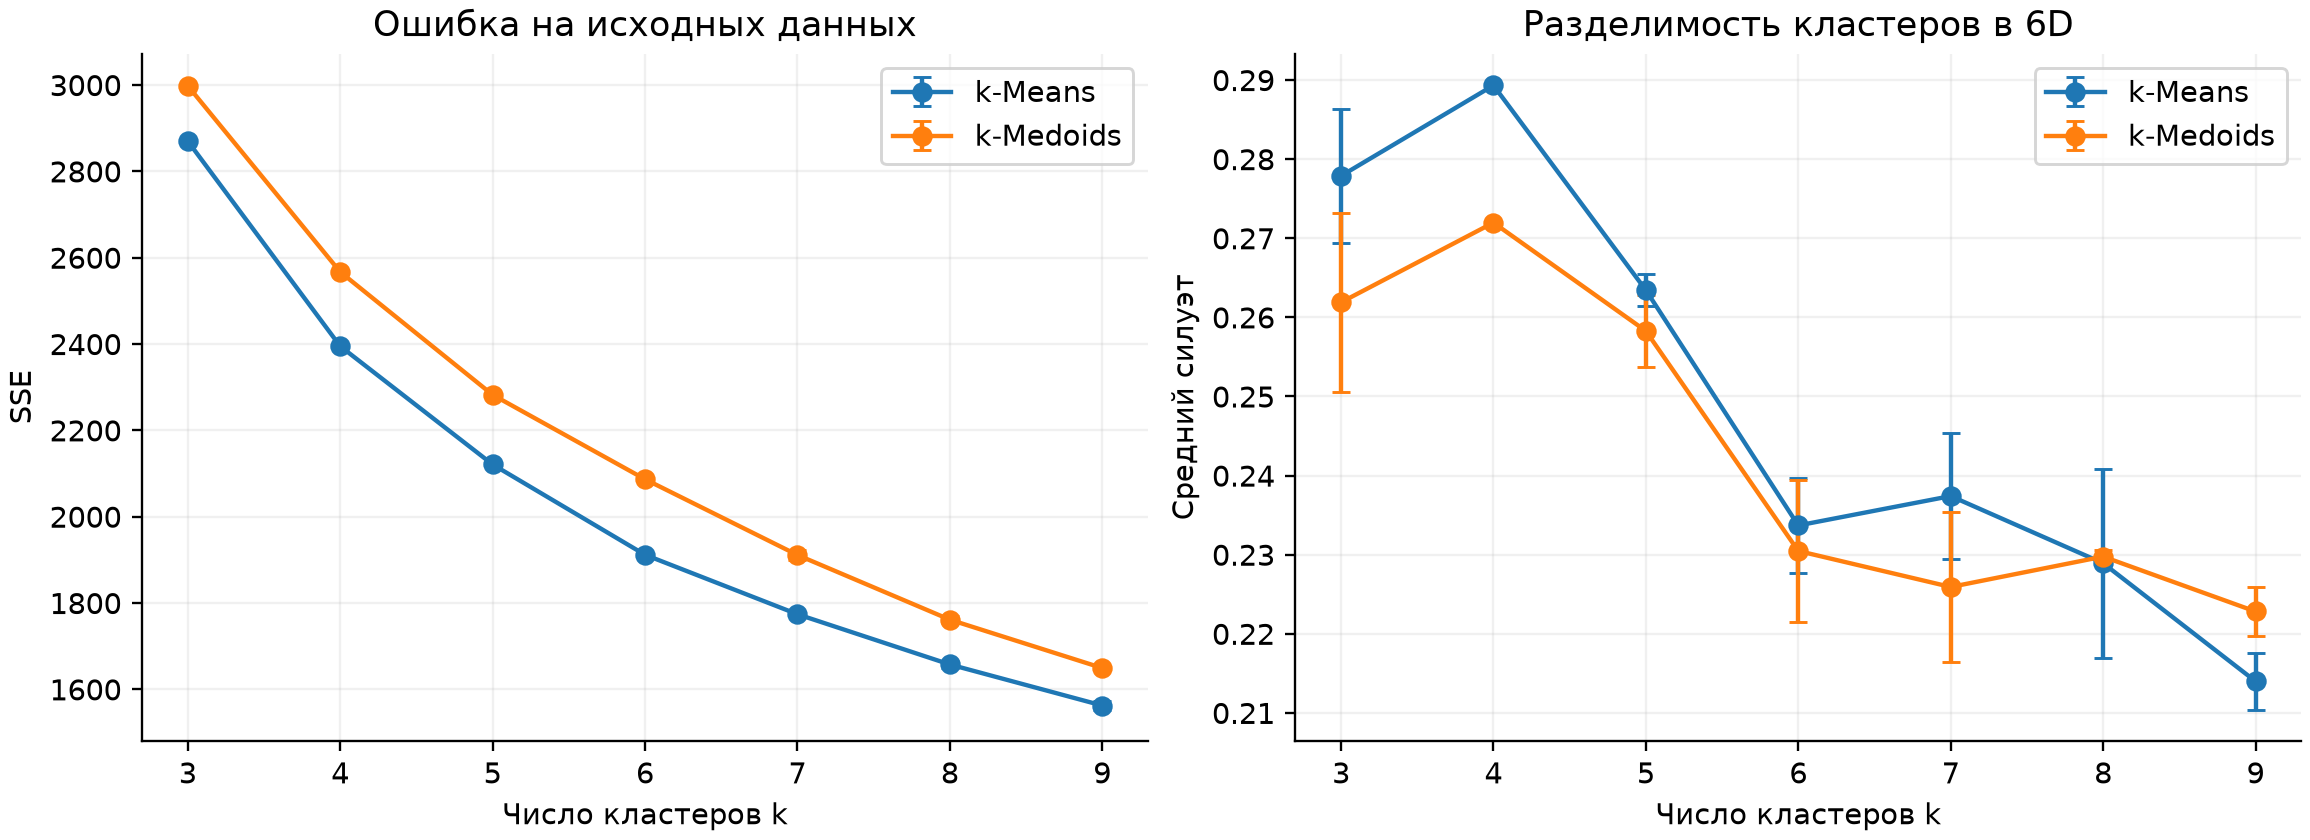

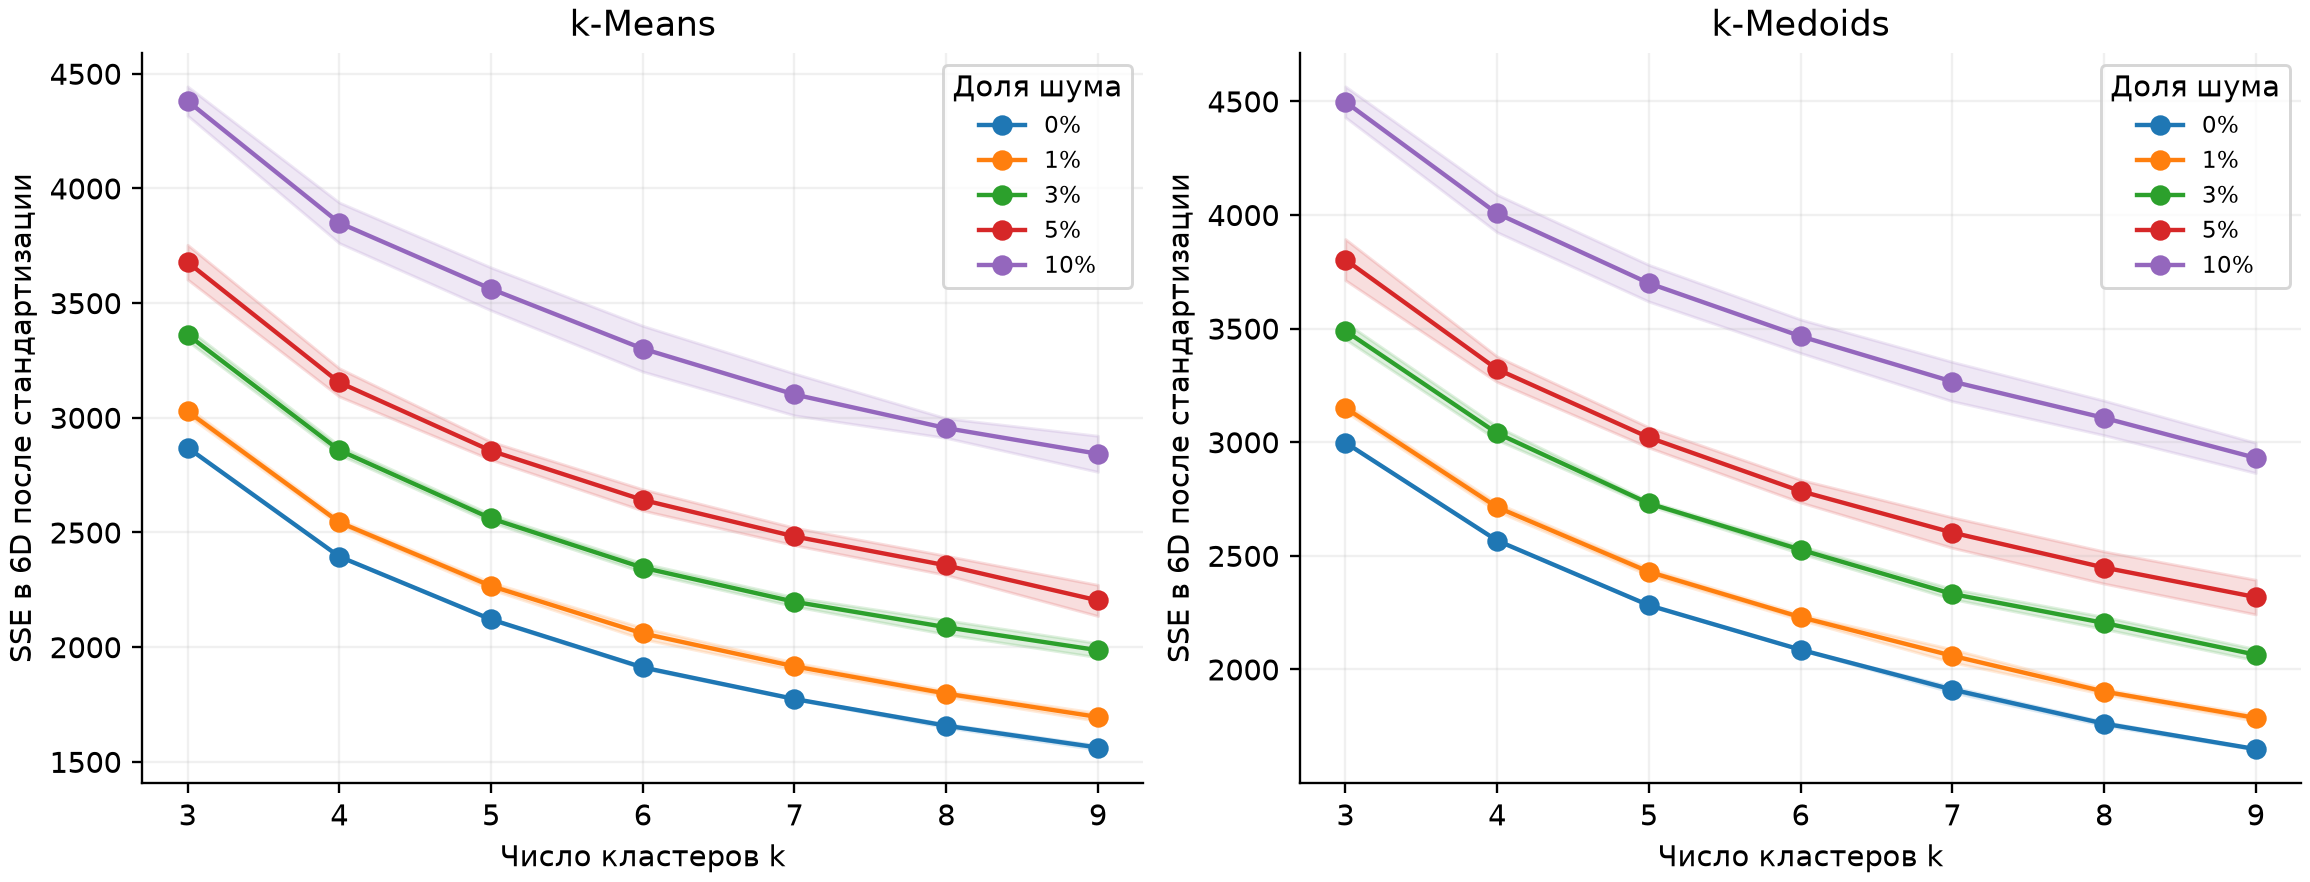

In [8]:
explained = make_figures(metrics, models, X_clean, ROOT / 'results/figures', chosen_k=K)
display(Image(filename=str(ROOT / 'results/figures/clean_metrics.png'), width=1100))
display(Image(filename=str(ROOT / 'results/figures/error_by_k.png'), width=1100))
for algorithm in ALGORITHMS:
    row = summary[(summary.algorithm == algorithm) & (summary.noise == 0)].sort_values('silhouette_mean').iloc[-1]
    print(f'{NAMES[algorithm]}: максимальный средний силуэт {row.silhouette_mean:.4f} при k={int(row.k)}')

## Точечные графики и интерпретация

PCA используется только для показа результатов: алгоритмы обучались на всех
шести признаках. Две фиксированные компоненты сохраняют около 75.6% дисперсии
customers; перекрытие проекций не равно совпадению кластеров в 6D. Цвет означает
кластер, крест — центроид, ромб — медоид. Номера кластеров условны; цвета
согласованы по максимальному пересечению с исходным k-Means при том же k.
Черная окружность отмечает поврежденную строку. На шумных панелях пределы осей
фиксированы и включают все объекты.

PC1=51.21%; PC2=24.36%; сумма=75.56%


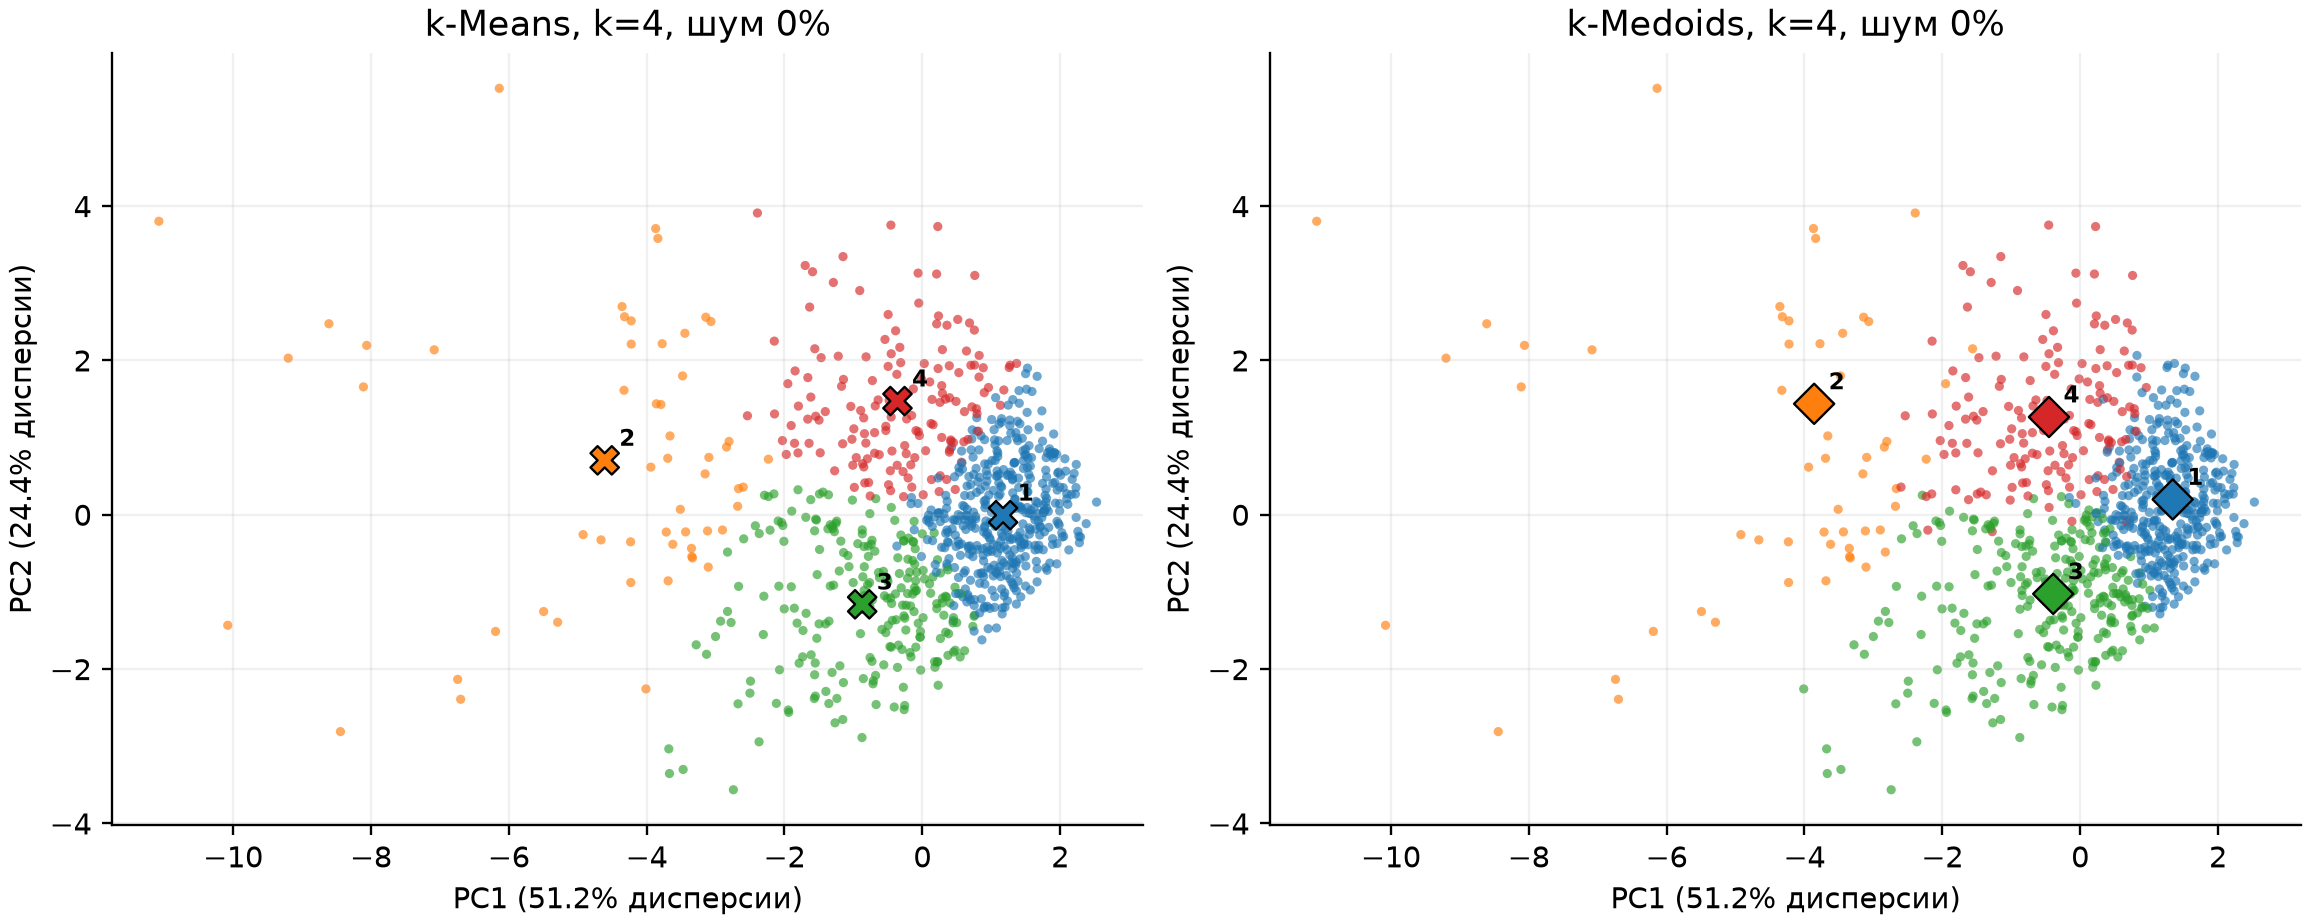

,n,Age,YearsEmployed,Income,CardDebt,OtherDebt,DebtIncomeRatio
1,426,30.552,4.854,29.019,0.644,1.394,7.321
2,55,43.473,18.218,126.945,7.082,11.882,17.807
3,220,42.482,15.059,67.859,1.502,3.116,7.417
4,149,33.711,6.027,36.248,2.322,4.591,19.570


In [9]:
print(f'PC1={explained[0]:.2%}; PC2={explained[1]:.2%}; сумма={sum(explained):.2%}')
display(Image(filename=str(ROOT / 'results/figures/clean_scatter.png'), width=1100))
baseline = models['kmeans', K, 0.0, 0]
profile = frame[FEATURE_COLUMNS].groupby(baseline.labels + 1).mean()
profile.insert(0, 'n', np.bincount(baseline.labels))
display(profile.round(3))
profile.to_csv(ROOT / 'results/cluster_profile.csv', index_label='cluster')

При k=4 для встроенного customers выделяются: большая группа более молодых
клиентов с меньшим доходом и долгами; небольшая группа с высоким доходом и
крупными долгами; более старшие клиенты с большим стажем и умеренной долговой
нагрузкой; группа с повышенным отношением долга к доходу. Это описания средних
профилей, а не банковские решения и не предсказание банкротства.

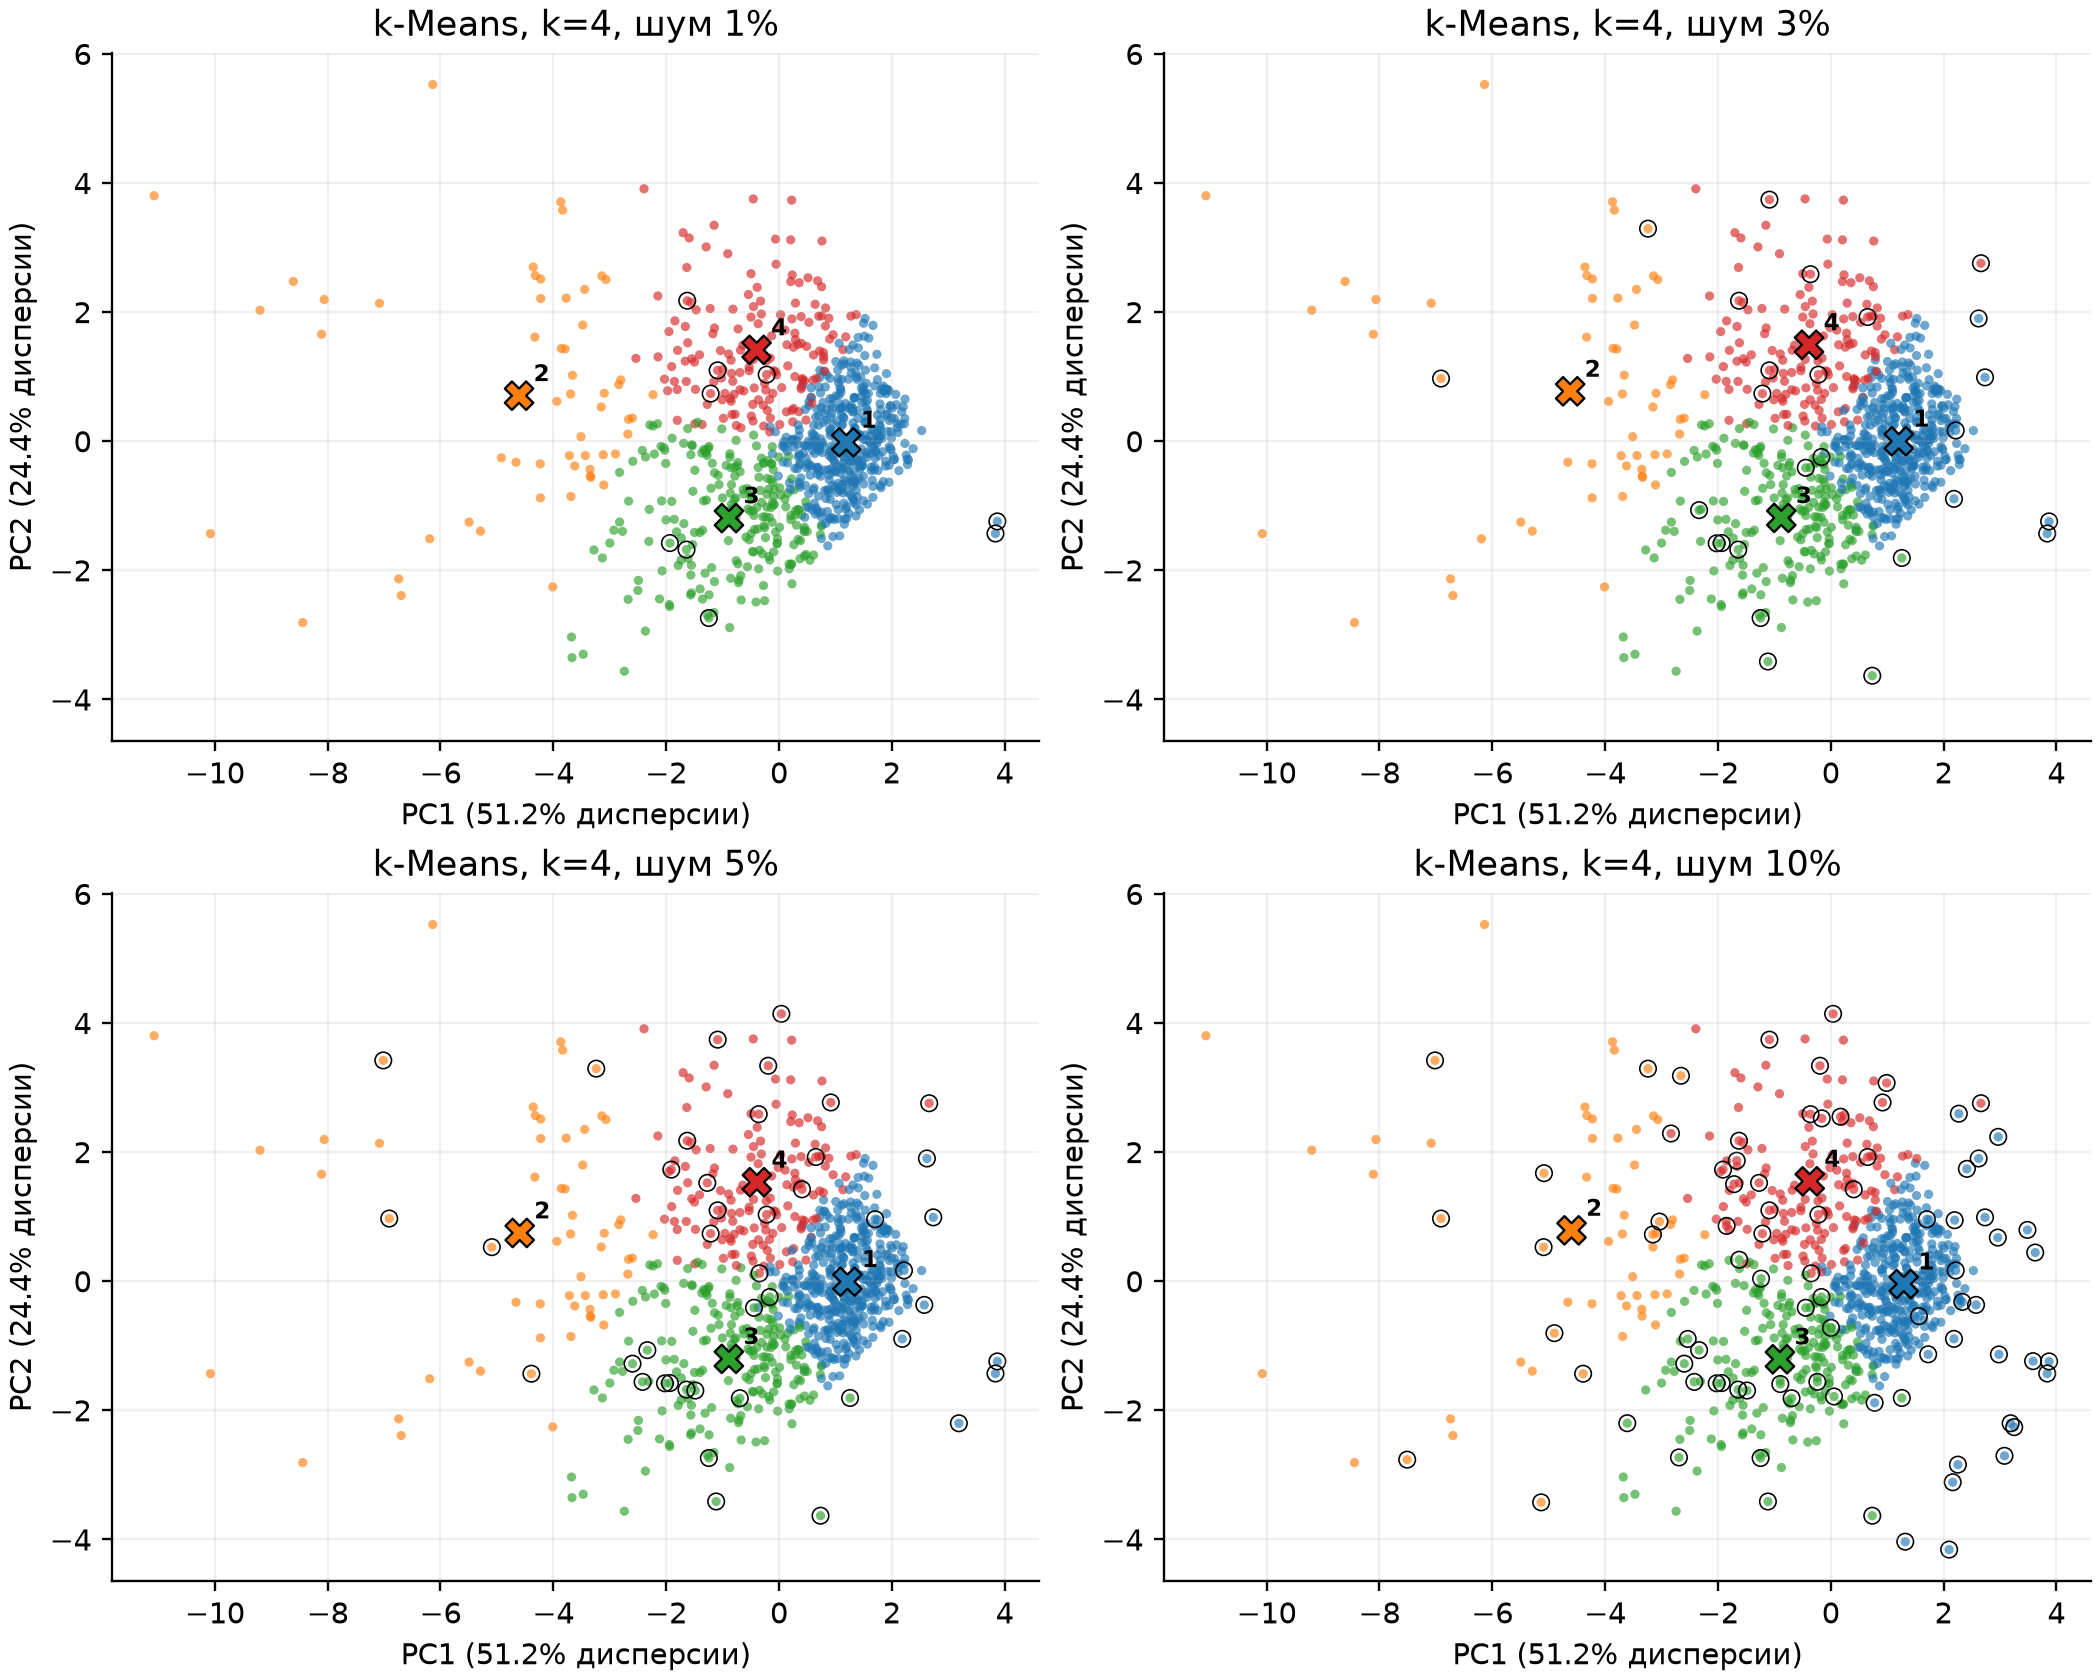

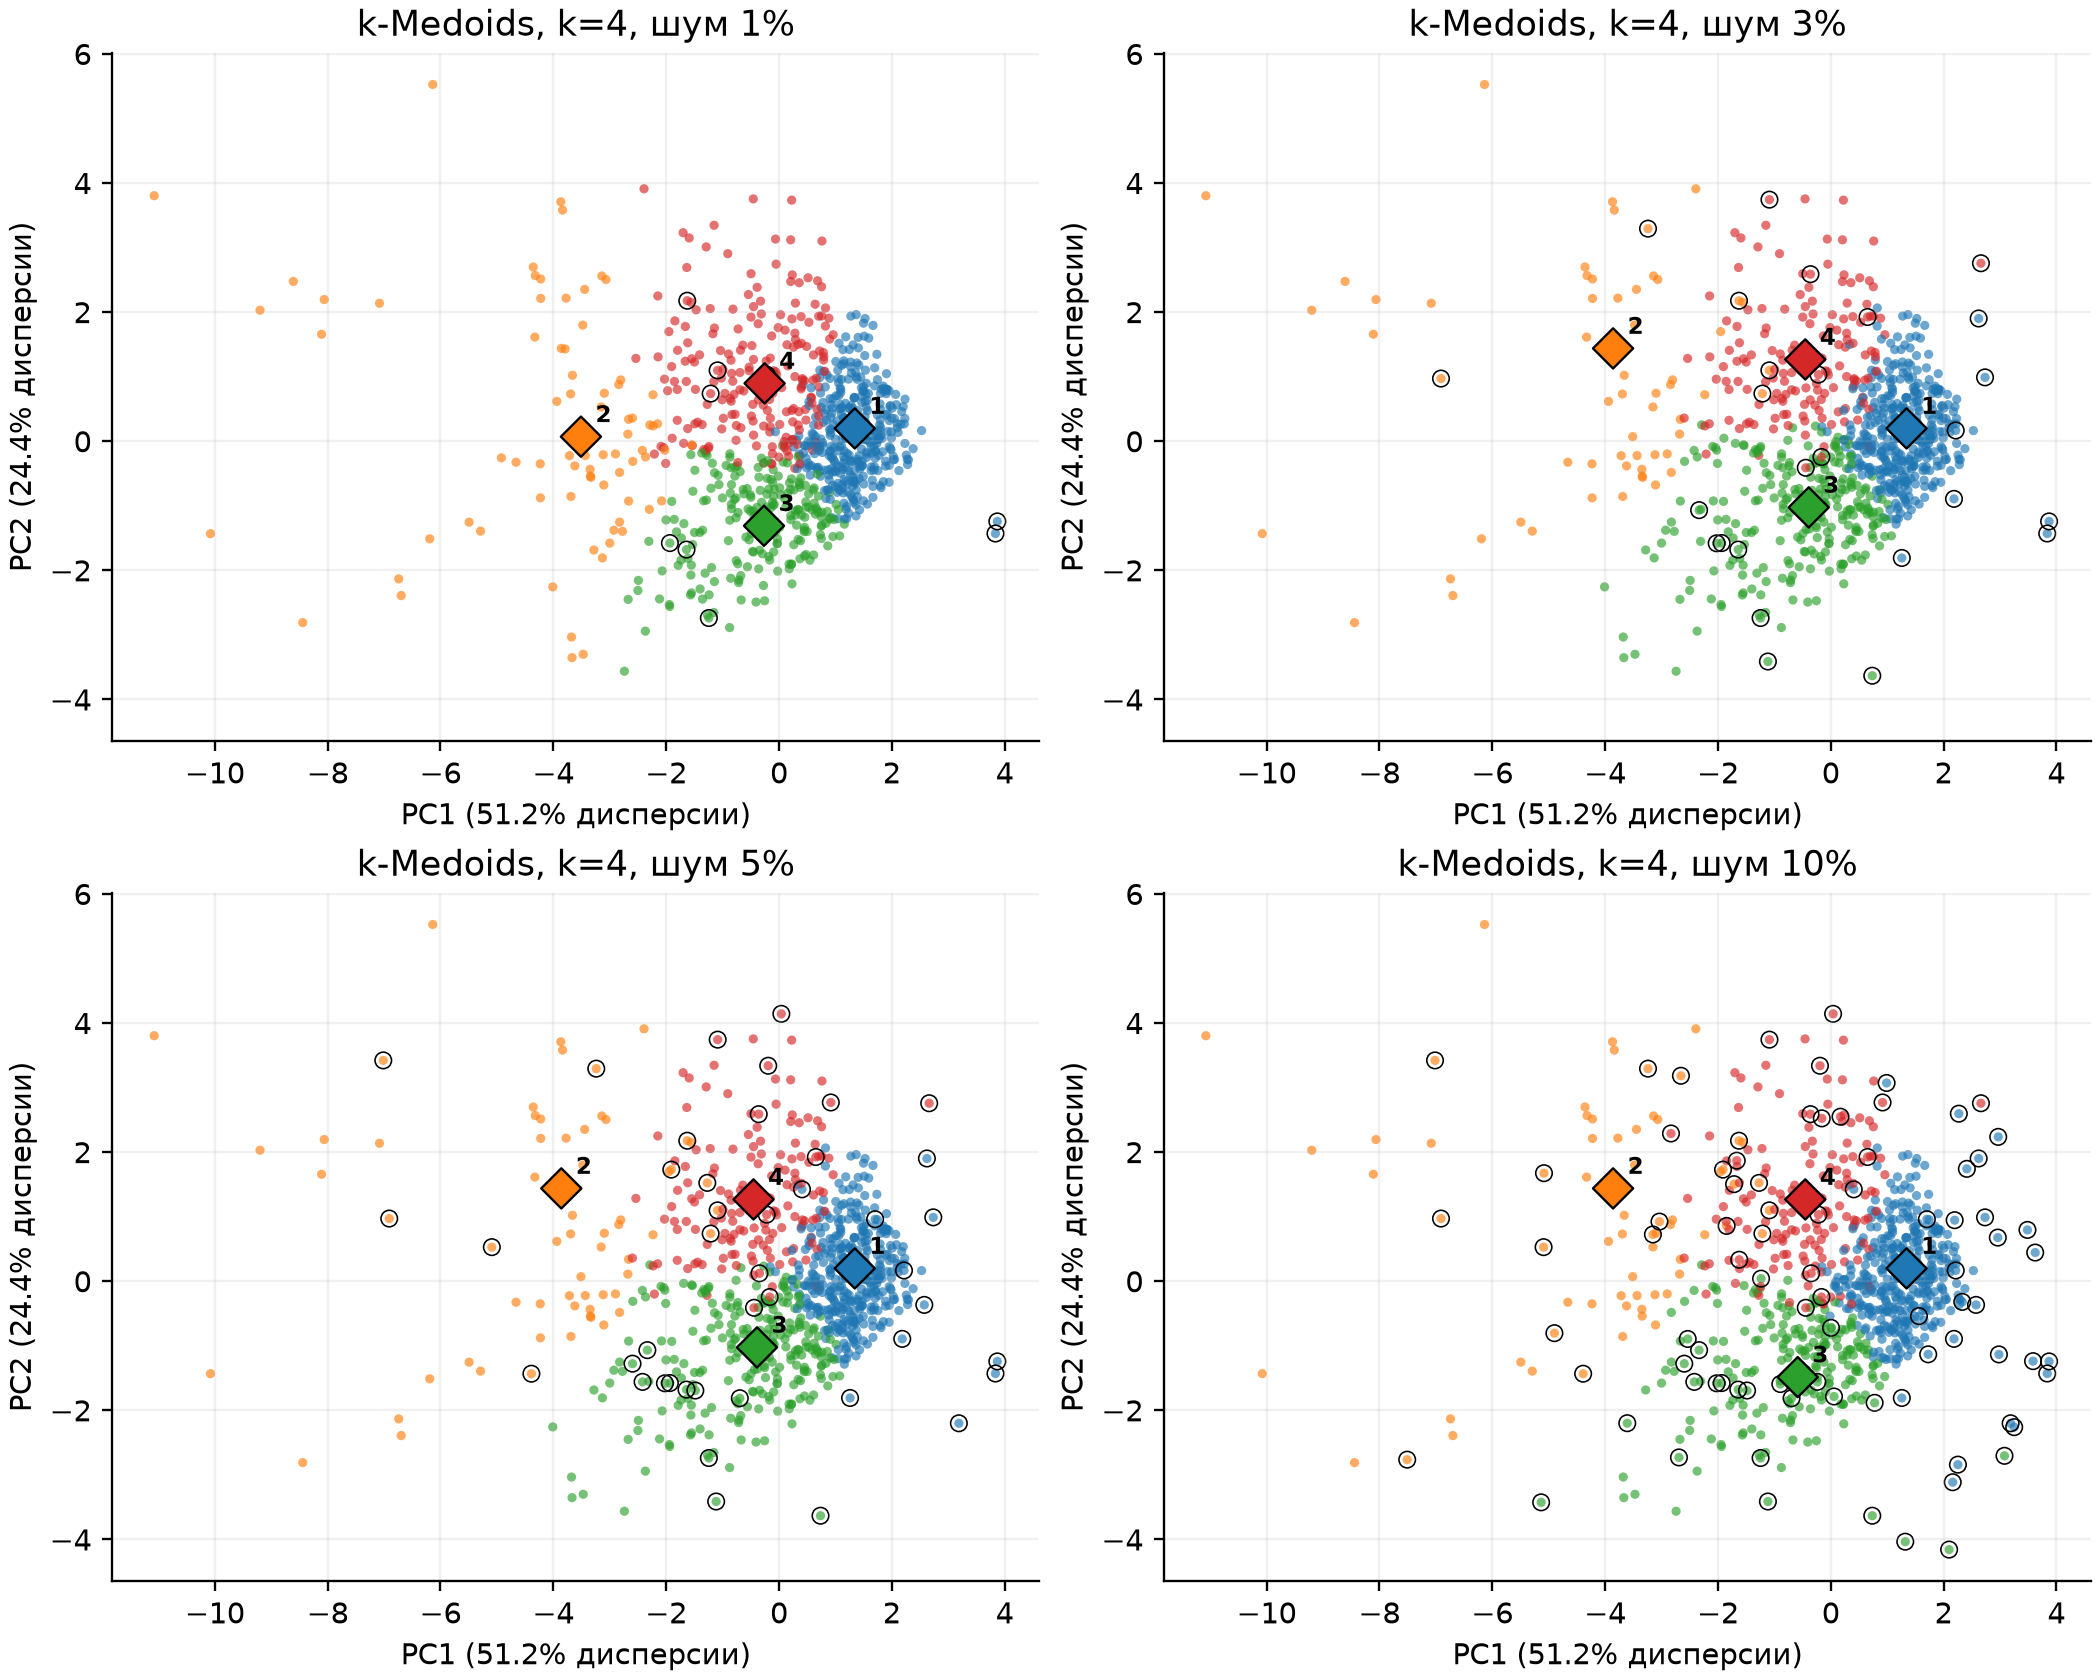

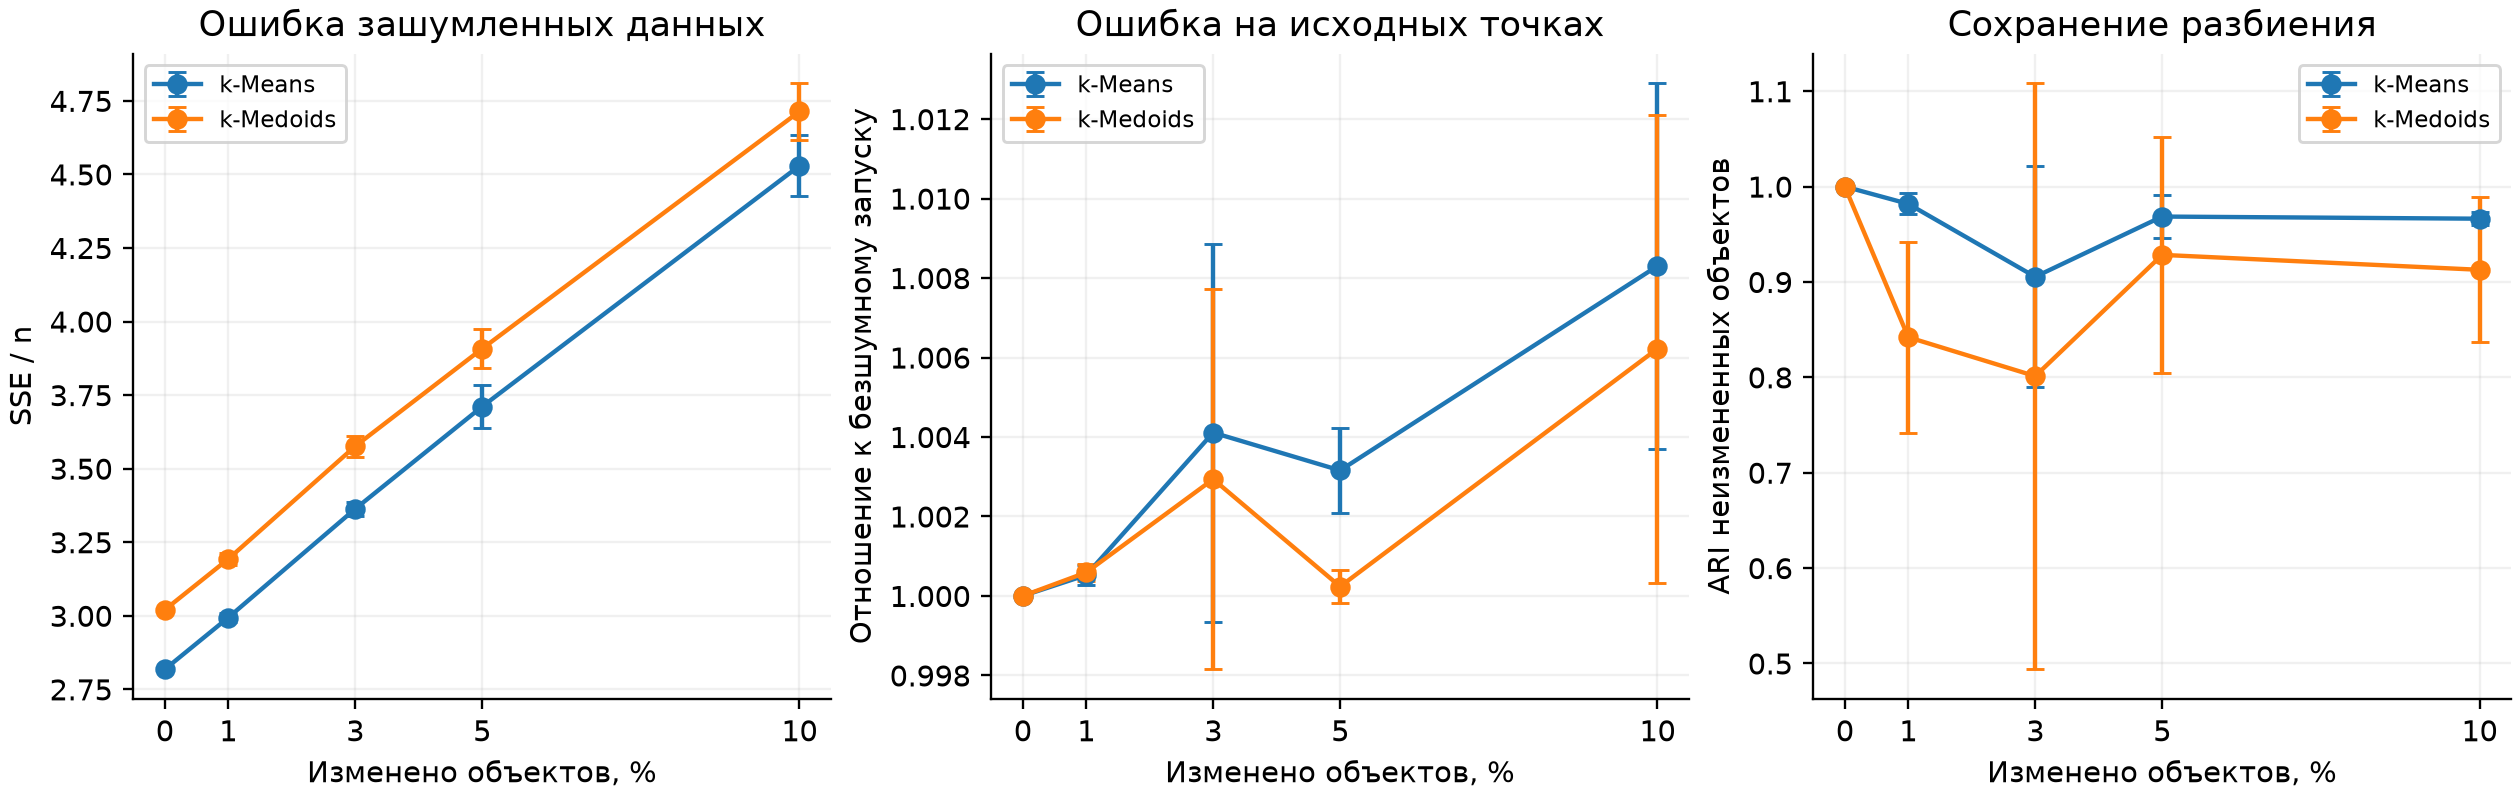

,algorithm,k,noise,sse_mean,sse_std,silhouette_mean,silhouette_std,ari_mean,ari_std,clean_mse_mean,clean_mse_std,changed_rows
5,kmeans,4,0.00,2395.0252,0.0100,0.2893,0.0001,1.0000,0.0000,2.8177,0.0000,0
6,kmeans,4,0.01,2544.5969,13.4291,0.2845,0.0006,0.9819,0.0111,2.8192,0.0007,9
7,kmeans,4,0.03,2858.5537,19.9144,0.2765,0.0039,0.9054,0.1158,2.8293,0.0134,26
8,kmeans,4,0.05,3154.1692,61.3648,0.2688,0.0079,0.9686,0.0223,2.8266,0.0030,43
9,kmeans,4,0.10,3849.8967,88.3642,0.2509,0.0076,0.9663,0.0070,2.8411,0.0130,85
40,kmedoids,4,0.00,2567.1102,0.0000,0.2720,0.0000,1.0000,0.0000,3.0201,0.0000,0
41,kmedoids,4,0.01,2713.8028,18.4301,0.2595,0.0049,0.8421,0.1001,3.0219,0.0006,9
42,kmedoids,4,0.03,3039.5358,29.7919,0.2586,0.0033,0.8012,0.3075,3.0290,0.0145,26
43,kmedoids,4,0.05,3321.3014,56.0184,0.2494,0.0080,0.9284,0.1240,3.0208,0.0012,43
44,kmedoids,4,0.10,4006.7514,82.5382,0.2387,0.0088,0.9127,0.0760,3.0389,0.0178,85


In [10]:
for name in ['noise_kmeans', 'noise_kmedoids', 'noise_stability']:
    display(Image(filename=str(ROOT / f'results/figures/{name}.png'), width=1050))
display(summary[summary.k == K].round(4))

Рост SSE на шумных данных включает прямую цену больших сдвигов. Сравните его с
ошибкой на исходных точках и ARI: представители могут сдвигаться умеренно, хотя
общая SSE заметно выросла. ARI не обязан убывать монотонно: при новых повреждениях
оптимизатор может выбрать другое локальное решение. Квадратичный PAM на этом
наборе не показывает универсального превосходства по устойчивости над k-Means.
Силуэты около 0.27–0.29 на чистых данных указывают на частичное перекрытие групп;
разбиение на четыре группы является рабочим вариантом в исследованном диапазоне,
а не доказательством существования ровно четырех естественных сегментов.

## Галерея всех условий

По одному рисунку для каждого k от 3 до 9; столбцы соответствуют 0%, 1%, 3%, 5%,
10% шума, строки — двум алгоритмам. Все 850 точек каждого запуска показаны на
фиксированной PCA-проекции. Полные метки остальных повторов доступны в CSV.

### k = 3

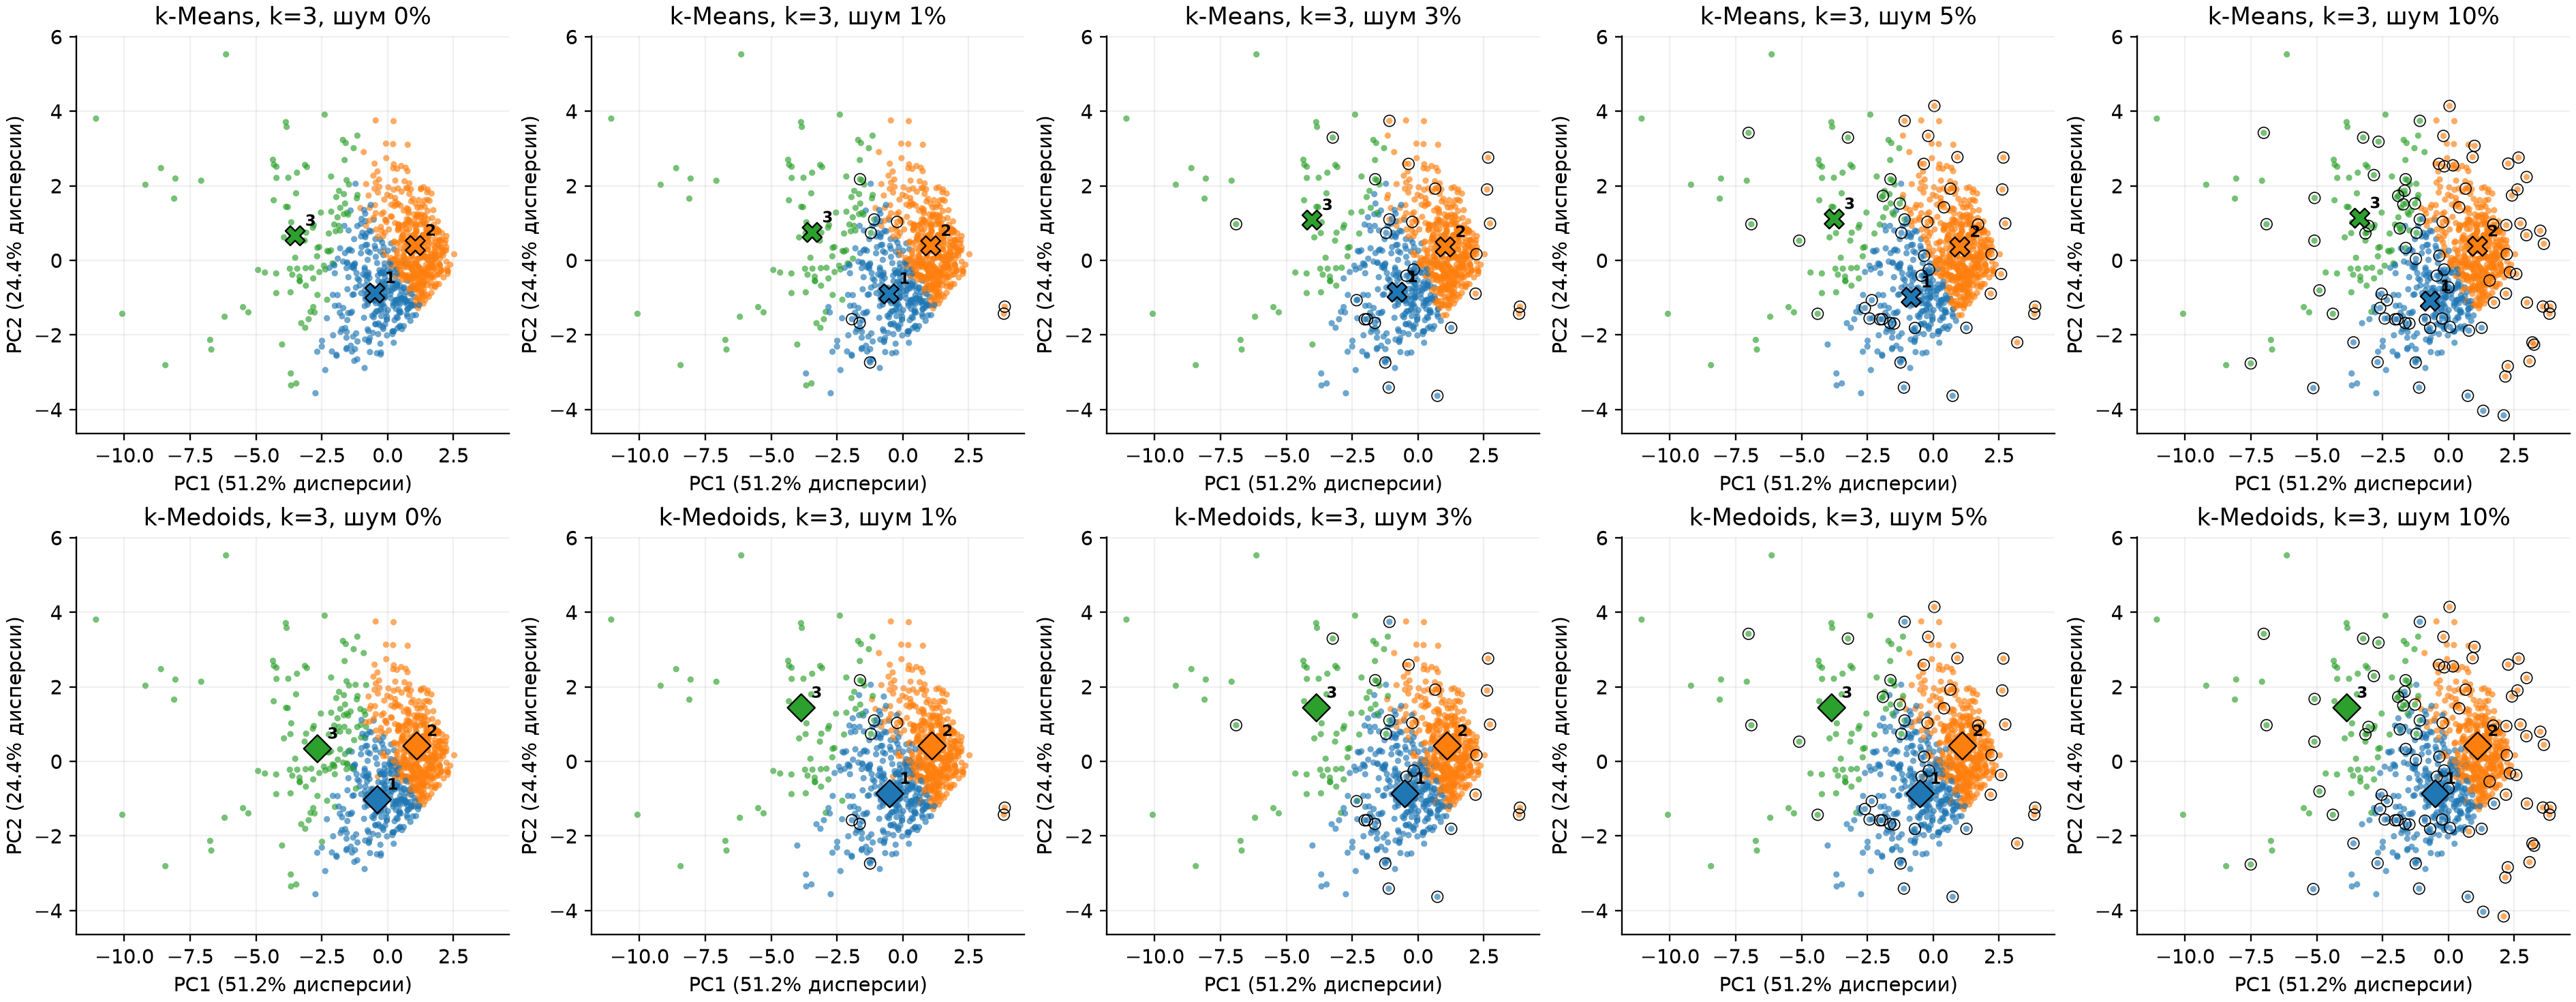

### k = 4

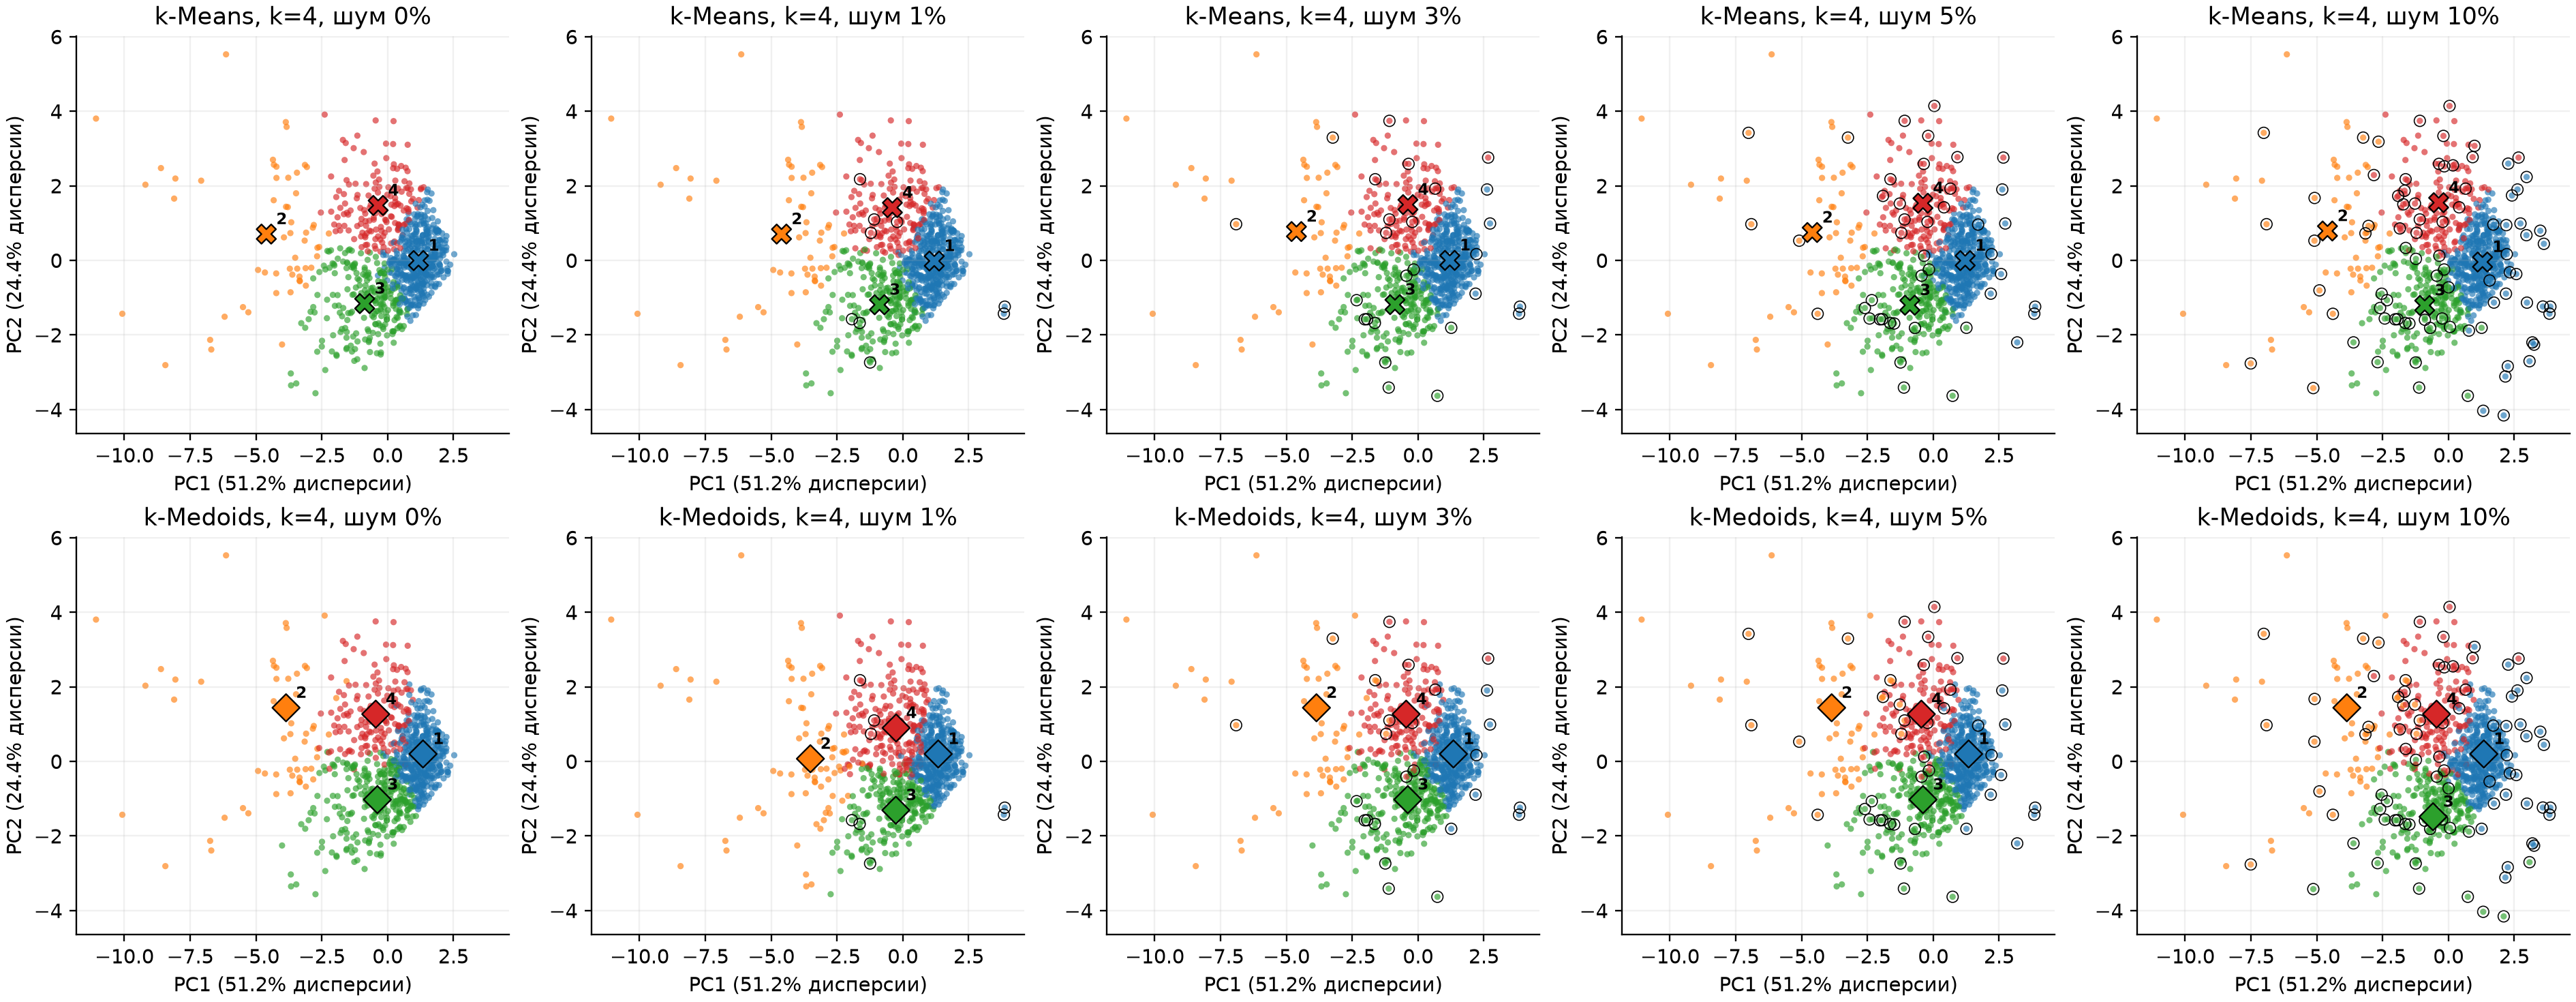

### k = 5

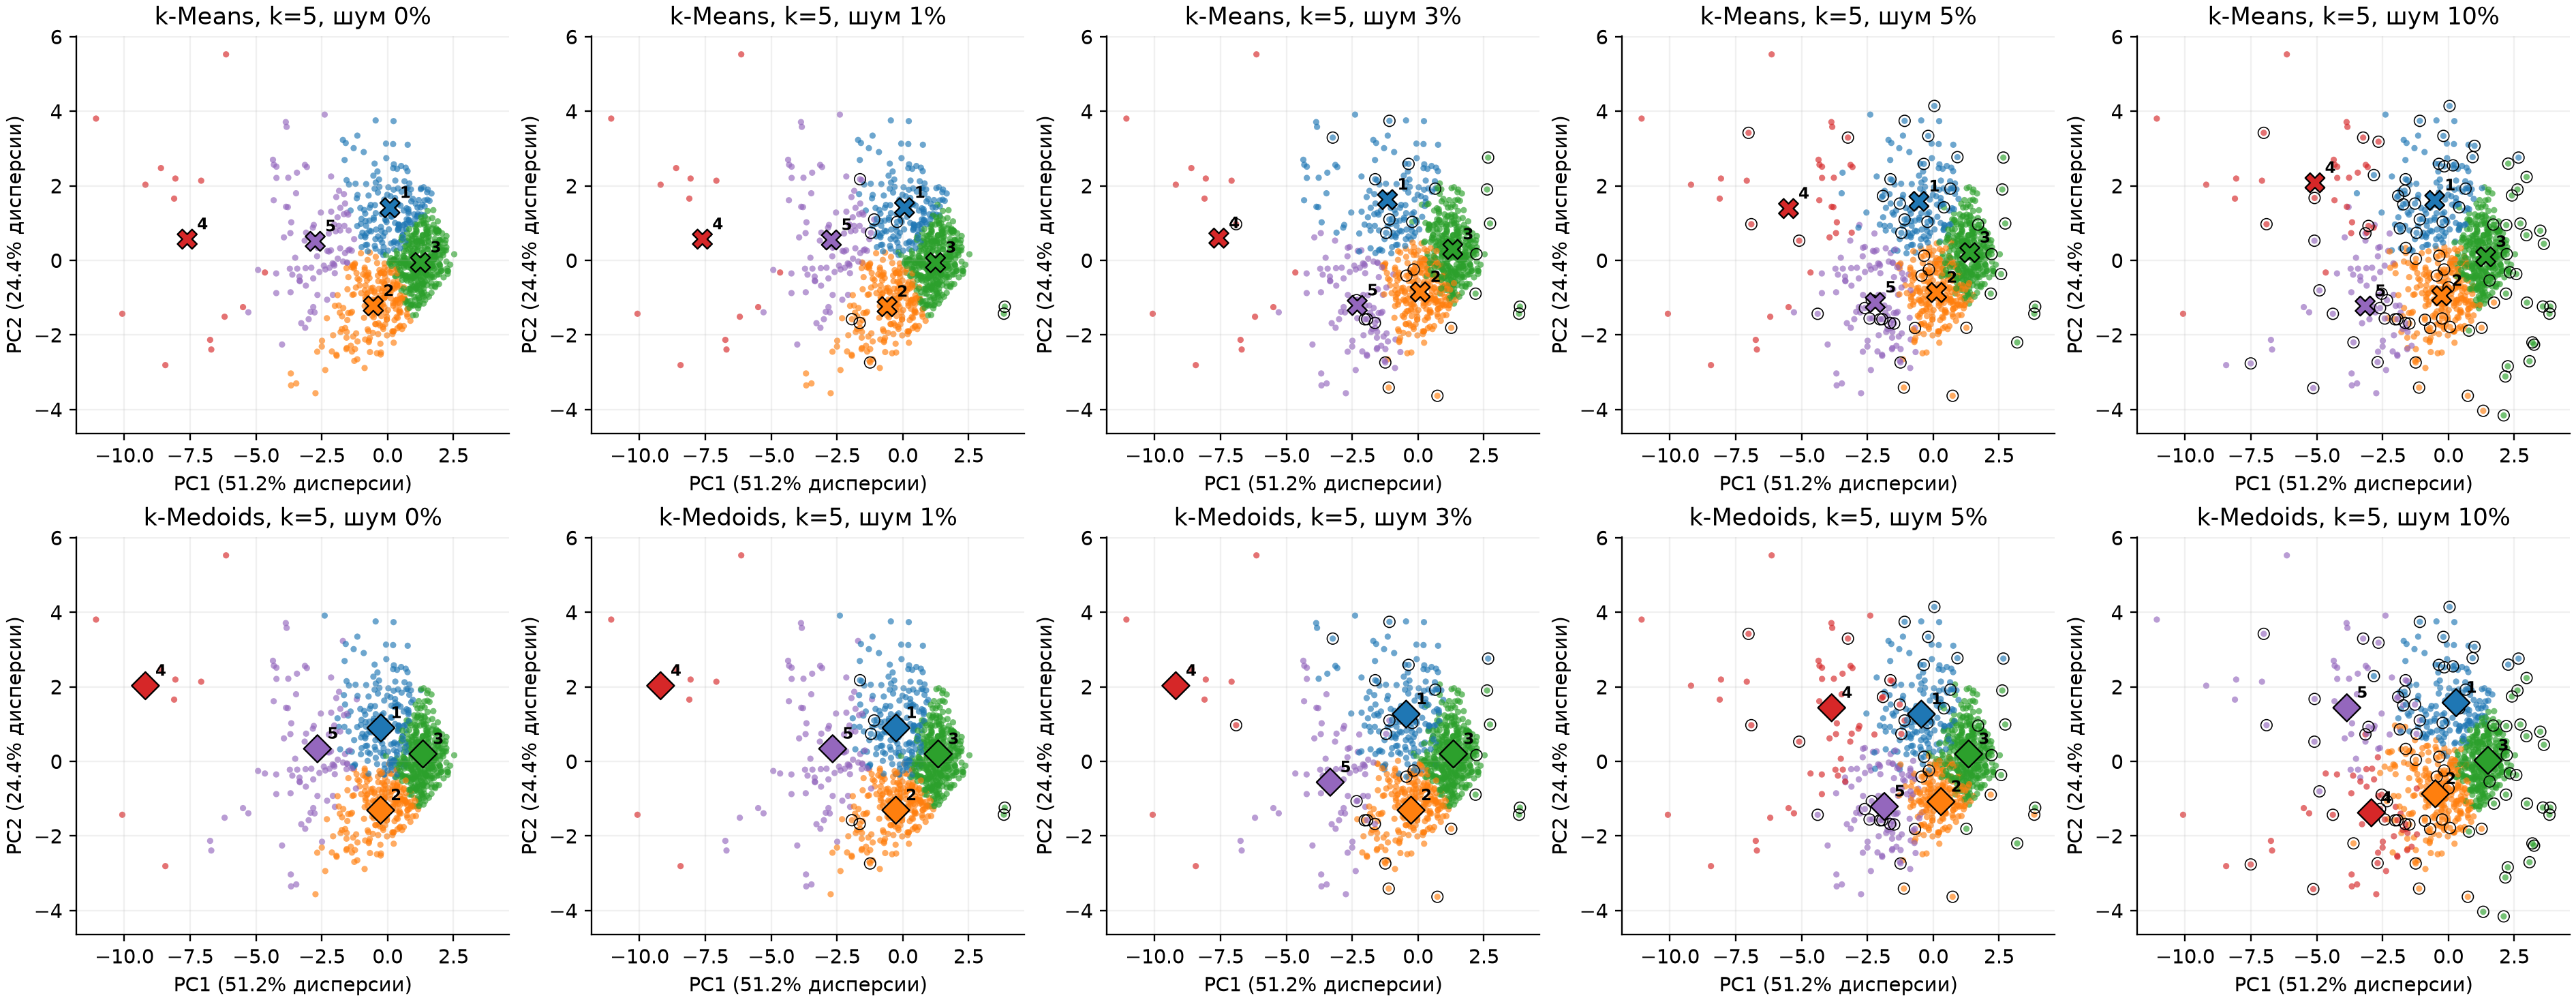

### k = 6

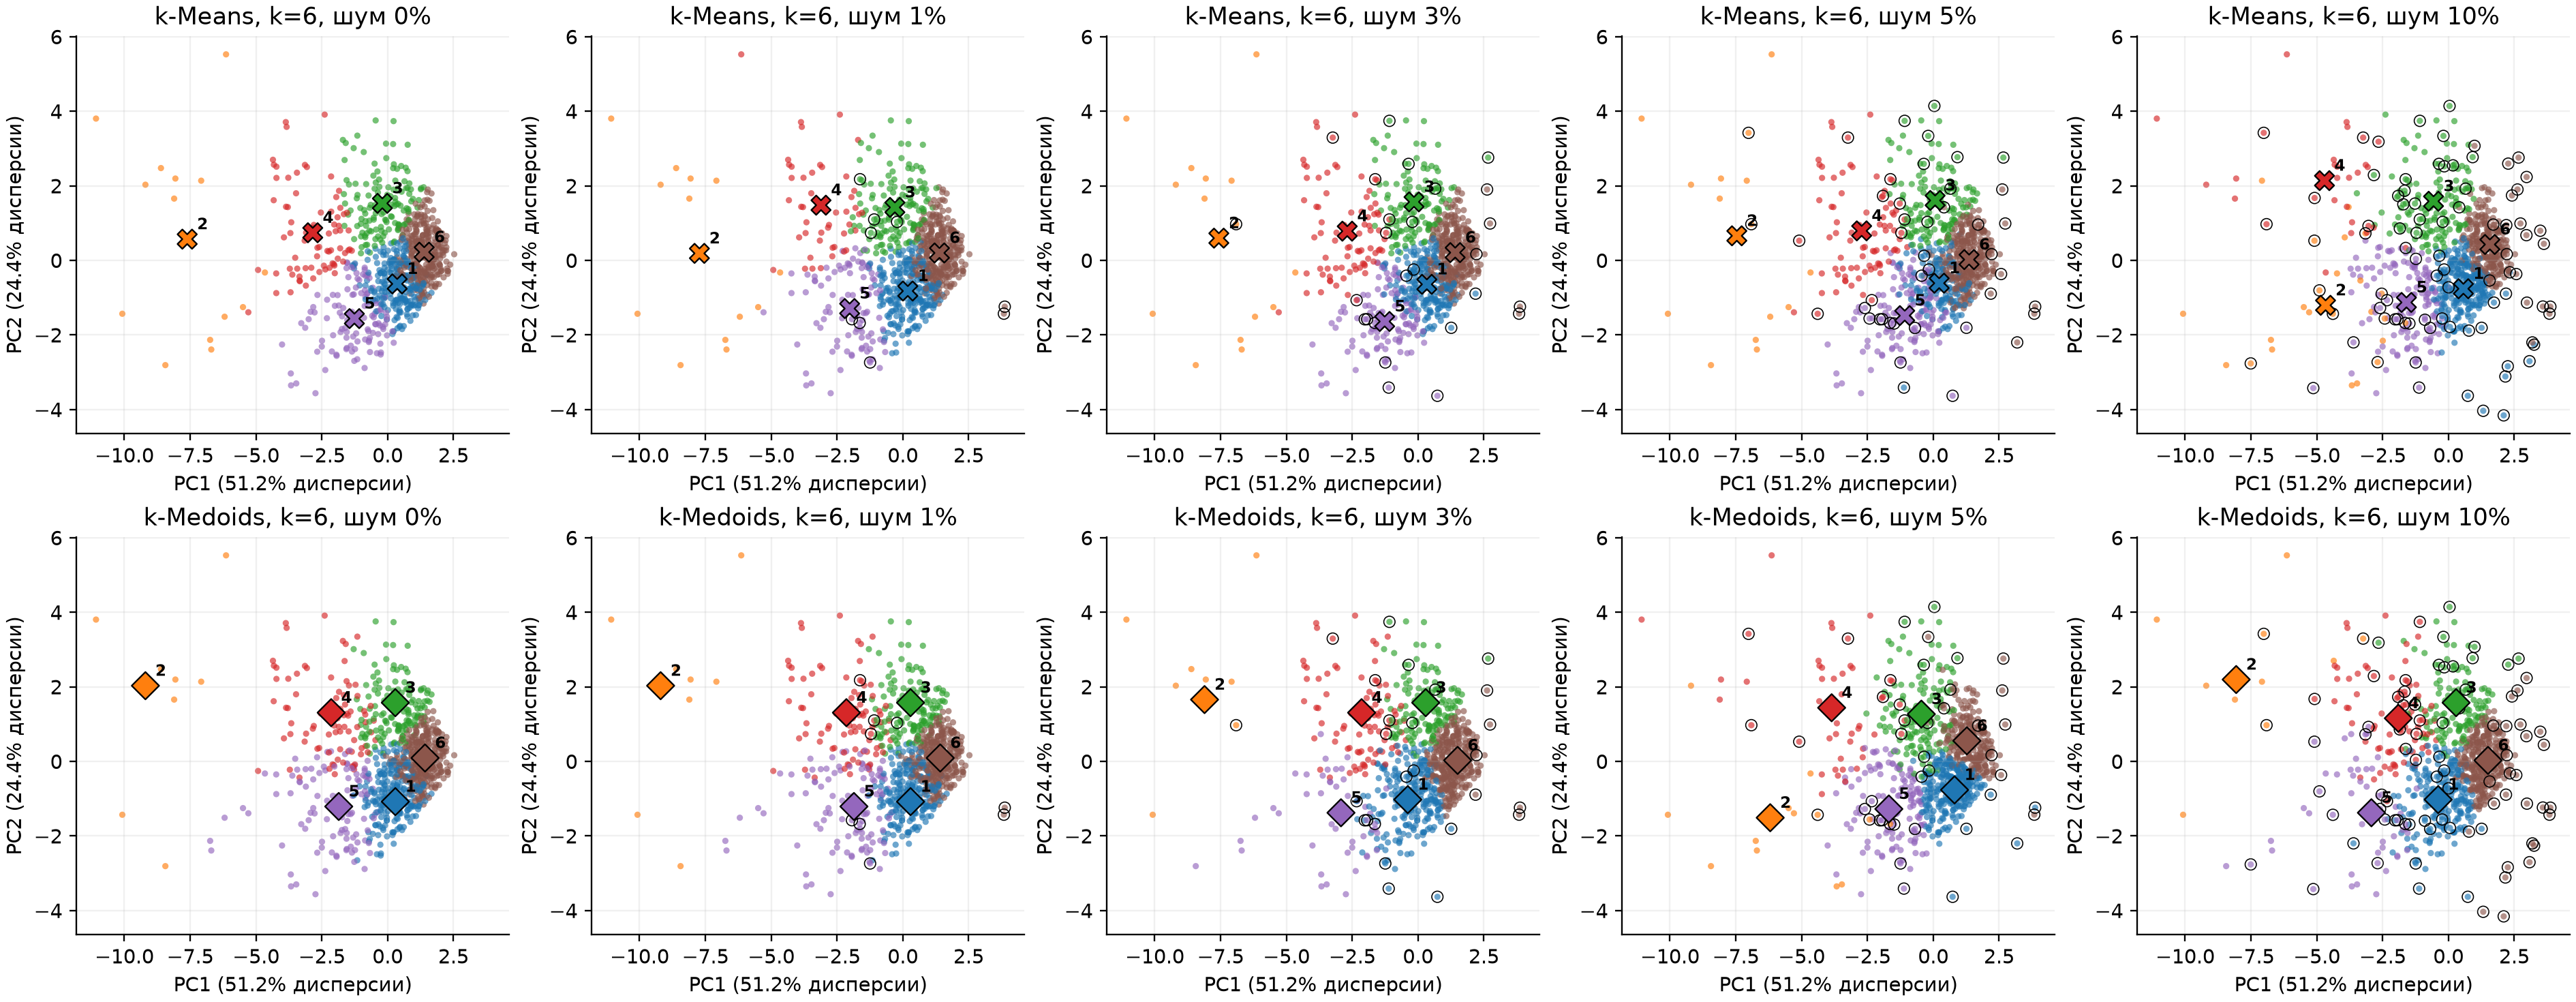

### k = 7

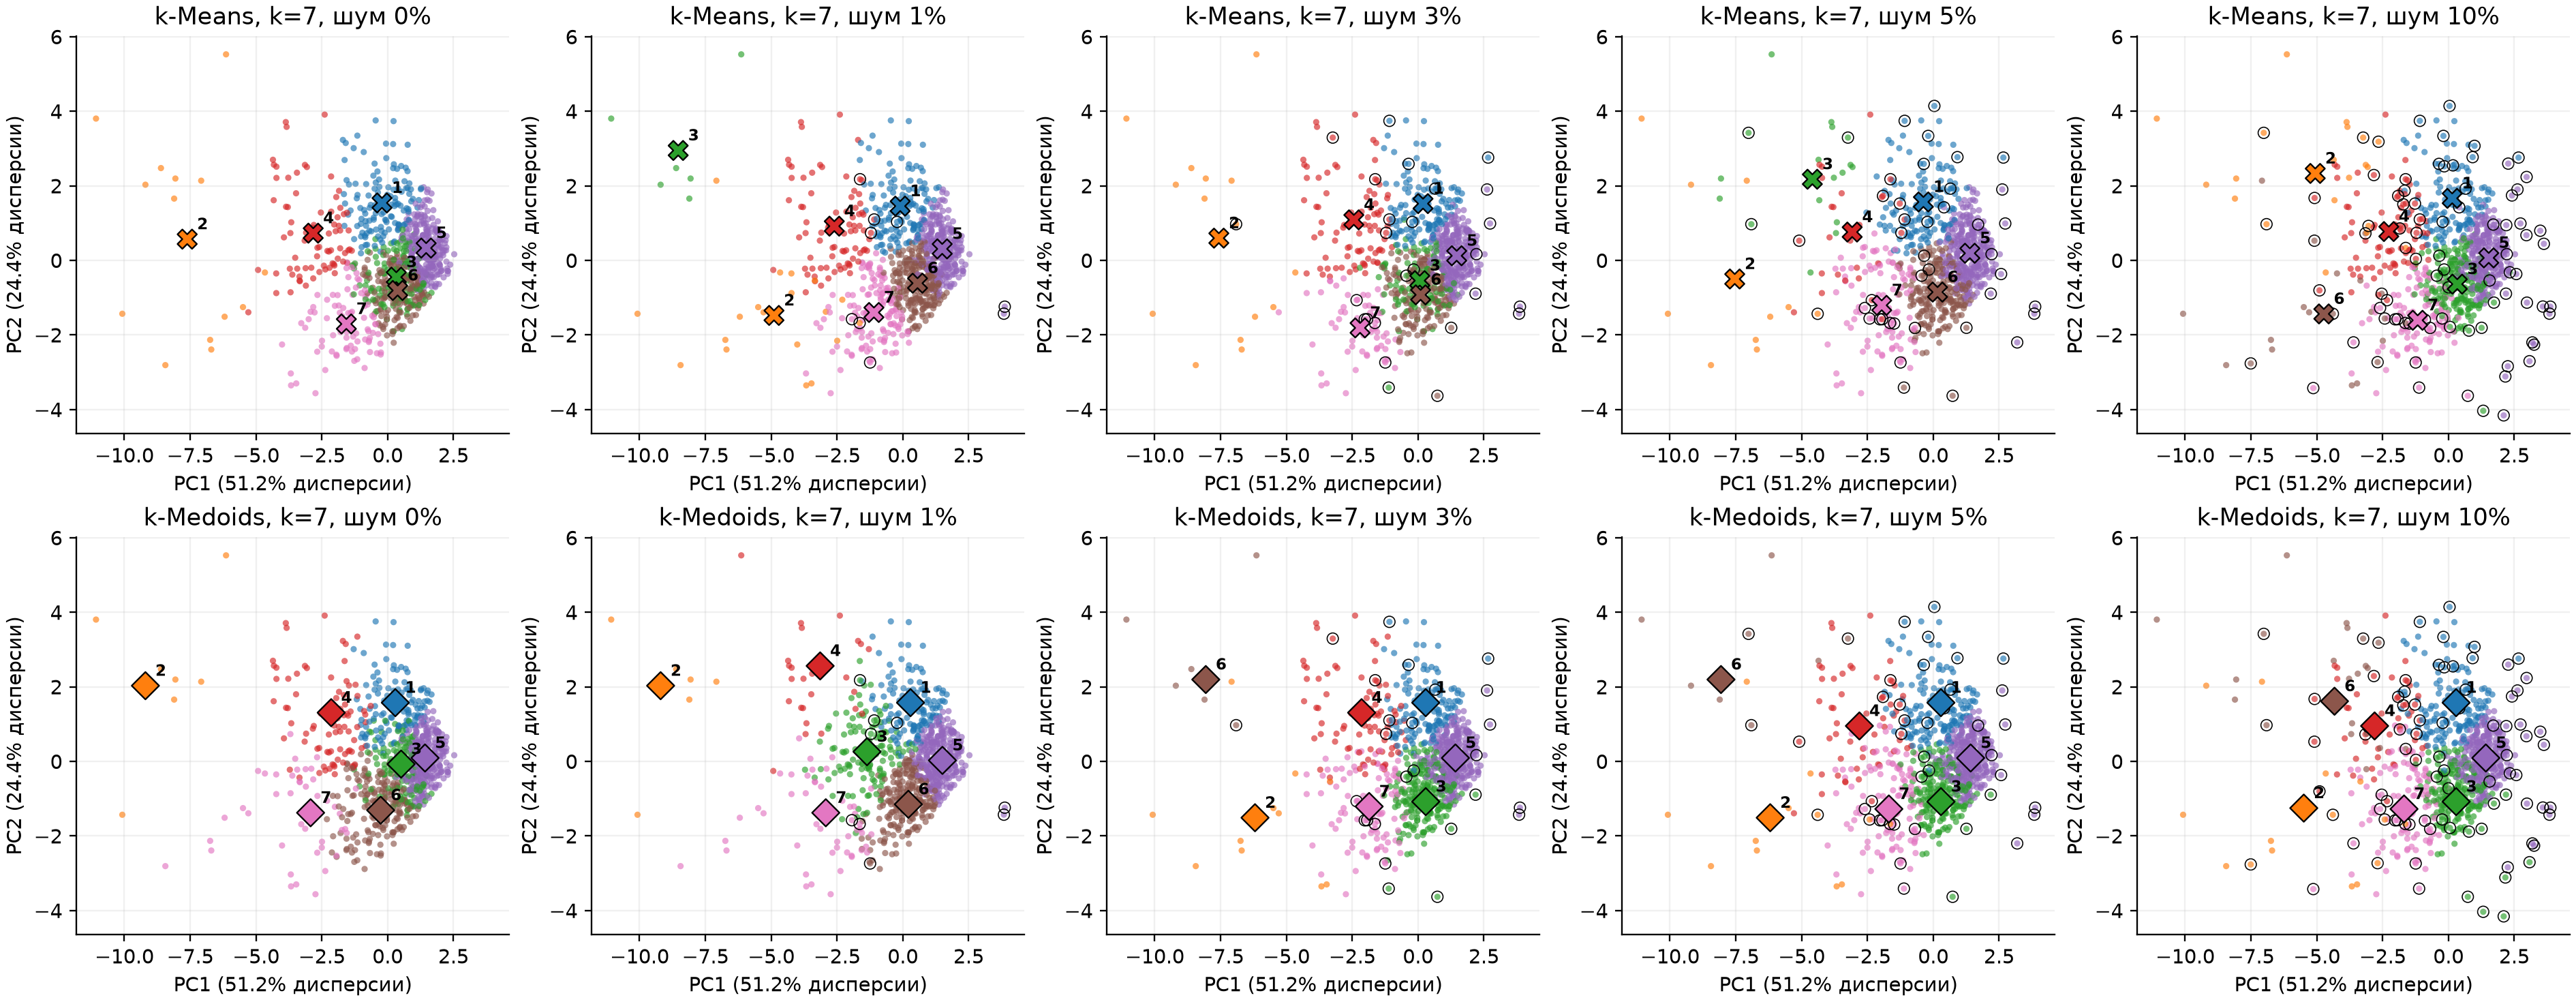

### k = 8

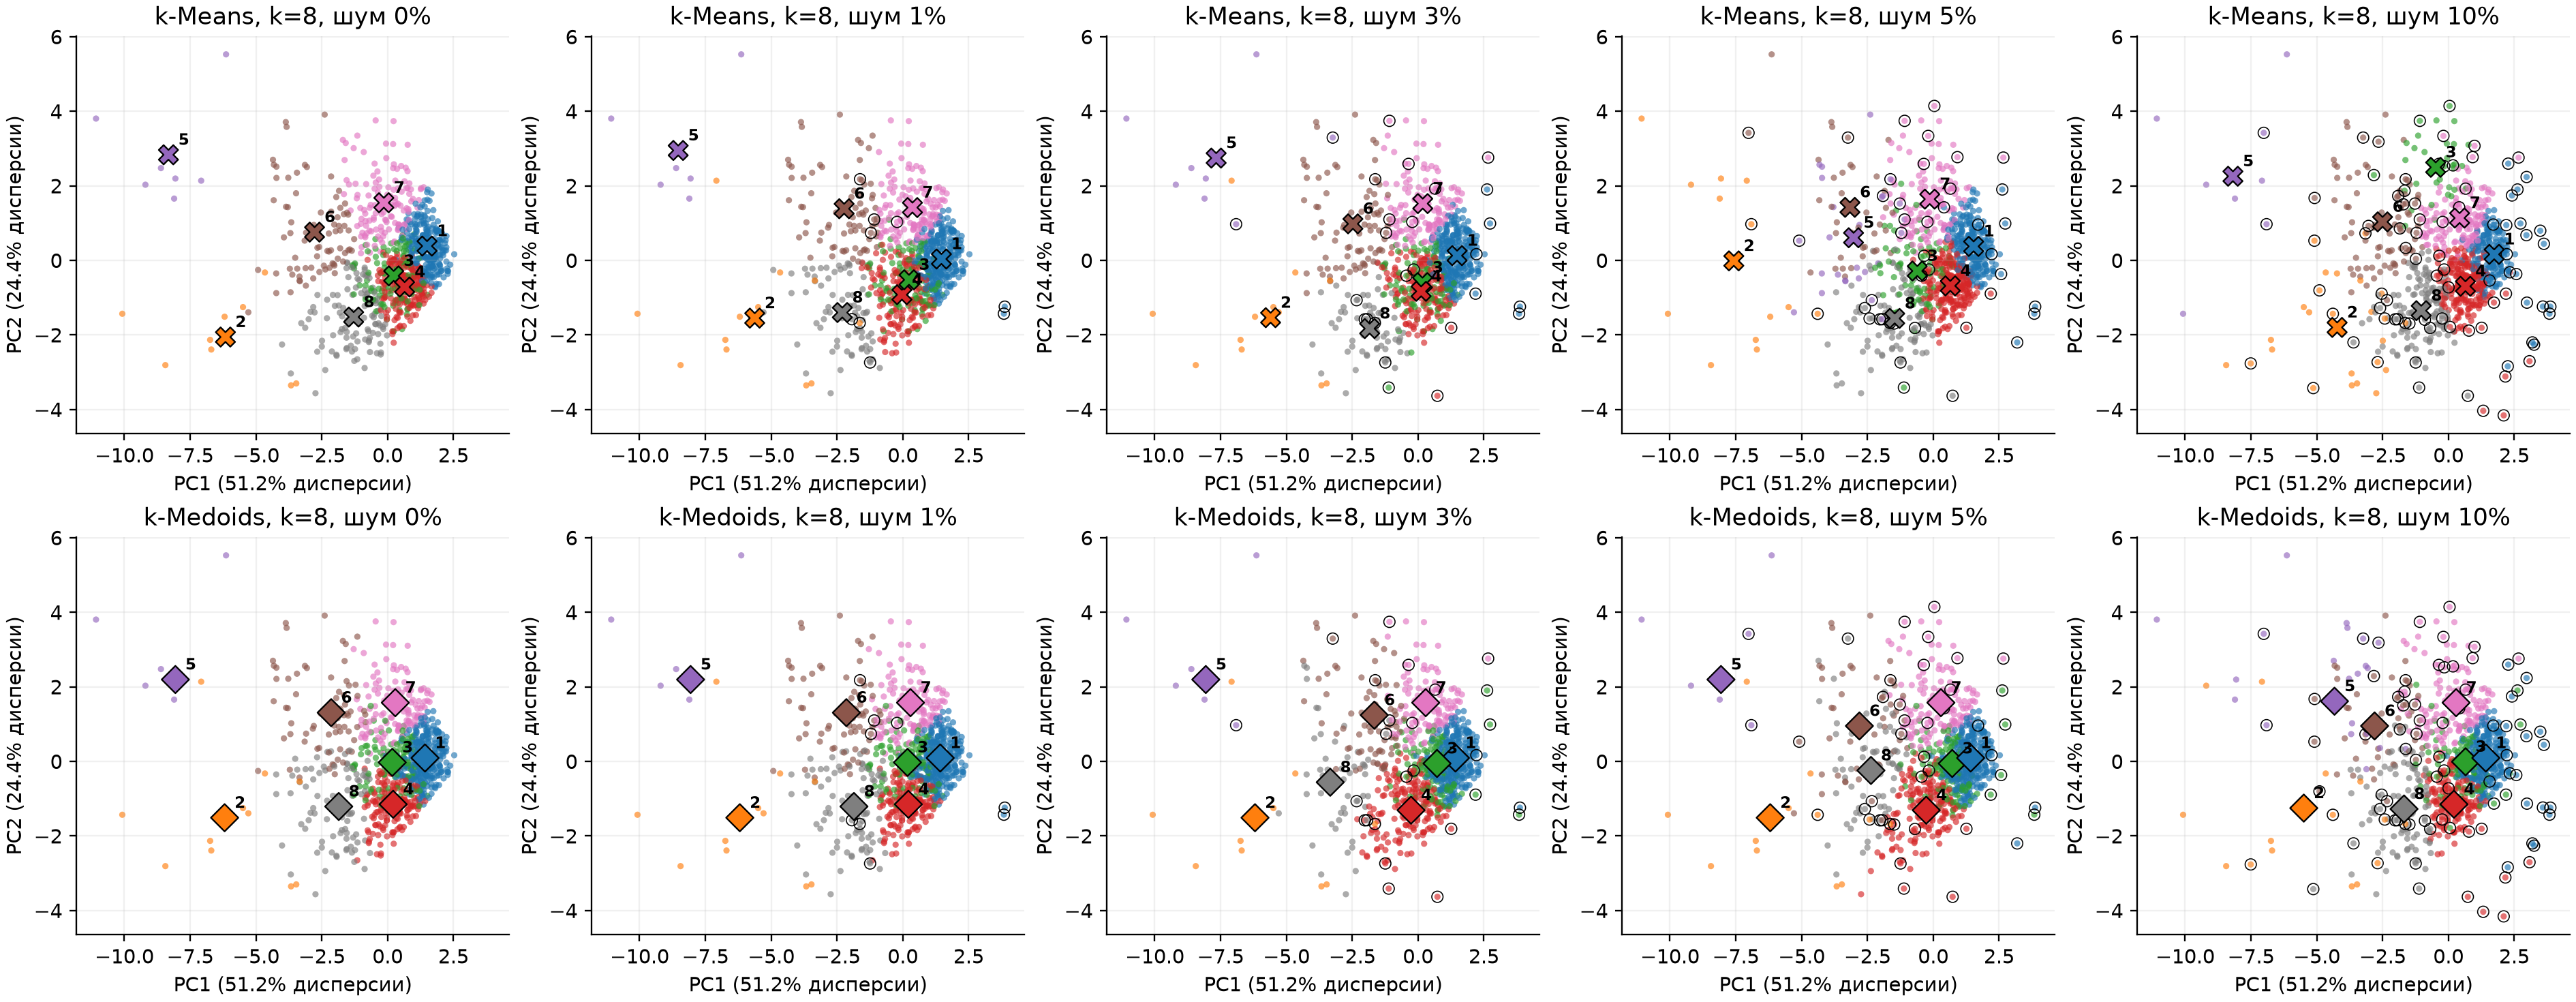

### k = 9

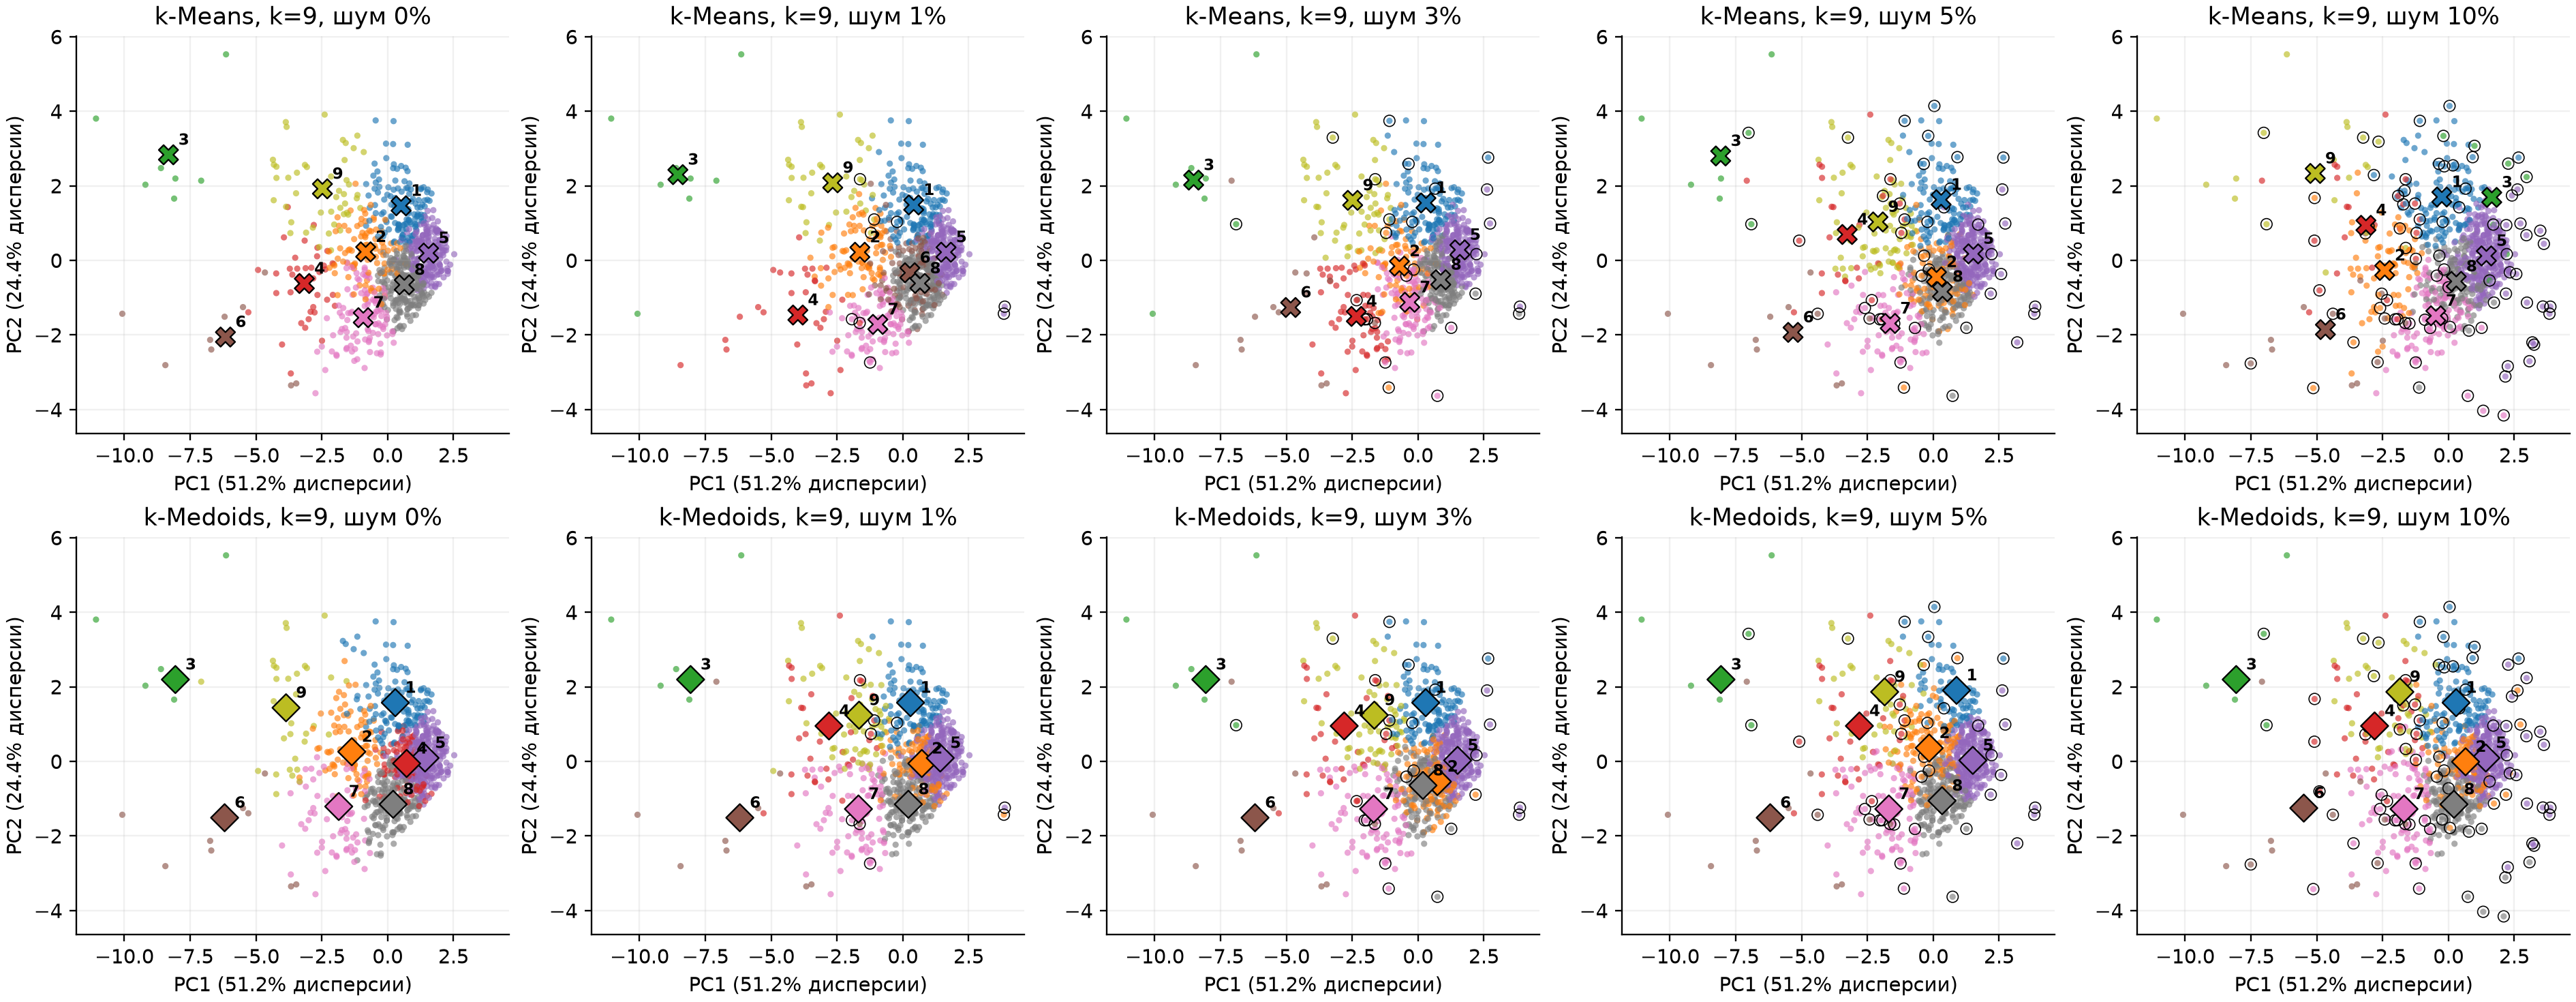

In [11]:
for k in KS:
    display(Markdown(f'### k = {k}'))
    display(Image(filename=str(ROOT / f'results/figures/all_conditions_k{k}.png'), width=1500))

## Дополнение про обычные расстояния PAM

Это отдельная проверка для k=4, шума 0% и 10%; она **не входит** в основную сетку.
При `power=1` PAM минимизирует $\sum_i\|z_i-m_{a_i}\|$, но для сравнения также
выводится SSE. Его собственная цель и SSE имеют разные единицы и не сопоставляются
как одна величина. Даже при обычных расстояниях выигрыш по ARI не гарантирован
для каждого набора и каждой модели шума.

In [12]:
classic_records = []
for seed in SEEDS:
    classic_baseline = None
    for p in [0.0, 0.1]:
        noisy, mask = add_noise(X_clean, p, seed)
        classic = pam(noisy, K, seed, n_init=N_INIT, power=1)
        if classic_baseline is None:
            classic_baseline = classic
        classic_records.append(dict(seed=seed, noise=p, sse=classic.sse,
            objective=classic.objective,
            clean_mse=squared_distances(X_clean, classic.centers).min(axis=1).mean(),
            ari=adjusted_rand_score(classic_baseline.labels[~mask], classic.labels[~mask])))
classic_results = pd.DataFrame(classic_records)
classic_results.to_csv(ROOT / 'results/classic_pam.csv', index=False)
display(classic_results.round(4))

,seed,noise,sse,objective,clean_mse,ari
0,2026,0.0,2654.1791,1238.4661,3.1226,1.0000
1,2026,0.1,4021.9367,1476.0117,3.0914,0.8518
2,2027,0.0,2670.7845,1239.4323,3.1421,1.0000
3,2027,0.1,4142.0041,1491.3059,3.1377,0.6014
4,2028,0.0,2654.1791,1238.4661,3.1226,1.0000
5,2028,0.1,4146.4880,1488.0075,3.0914,0.8545


## Сохранение материалов

`single_points.csv` содержит исходные поля, координаты до и после шума, метки и
индивидуальные ошибки. `all_points.csv.gz` содержит все 178500 назначений основной
сетки и шесть использованных координат. `metrics.csv` хранит 210 запусков,
`summary.csv` — 70 усредненных условий. `models.npz` хранит центры, метки,
медоиды и истории оптимизации. `preparation.json` хранит параметры стандартизации.
В архив также включается точная копия использованного CSV и исходный код.

In [13]:
(ROOT / 'clustering.py').write_text('"""Разделительная кластеризация: собственные Lloyd k-Means и PAM k-Medoids.\n\nВход: числовая матрица X размера (n, d), k, доля шумных строк.\nВыход: метки, представители, SSE, история оптимизации и таблица координат.\nКвадратичная цель PAM соответствует слайду 29 лекции 04. power=1 включает\nвариант с суммой обычных евклидовых расстояний. sklearn для обучения не нужен.\n"""\nfrom dataclasses import dataclass\nfrom pathlib import Path\nimport argparse\nimport json\nimport numpy as np\nimport pandas as pd\n\nFEATURES = ["Age", "YearsEmployed", "Income", "CardDebt", "OtherDebt", "DebtIncomeRatio"]\n\n\n@dataclass\nclass Fit:\n    """Результат: labels (n,), centers (k,d), SSE и значение целевой функции.\n\n    medoid_indices: индексы строк X либо None; history: убывающая цель лучшего\n    запуска; converged: достигнут ли критерий останова; iterations: число шагов.\n    """\n    labels: np.ndarray\n    centers: np.ndarray\n    sse: float\n    objective: float\n    history: list\n    converged: bool\n    iterations: int\n    medoid_indices: np.ndarray | None = None\n\n\ndef validate(X, k):\n    """Проверить конечную матрицу X и целое 1 <= k <= число уникальных строк."""\n    X = np.asarray(X, dtype=float)\n    if X.ndim != 2 or min(X.shape) == 0 or not np.isfinite(X).all():\n        raise ValueError("X должна быть непустой конечной двумерной матрицей")\n    if isinstance(k, bool) or int(k) != k or not 1 <= k <= len(np.unique(X, axis=0)):\n        raise ValueError("k должно быть целым от 1 до числа уникальных объектов")\n    return X, int(k)\n\n\ndef squared_distances(X, Y):\n    """Вернуть матрицу (len(X),len(Y)) квадратов евклидовых расстояний."""\n    # Прямое вычитание предотвращает потерю точности при больших координатах.\n    return np.sum((X[:, None, :] - Y[None, :, :]) ** 2, axis=2)\n\n\ndef initialize(X, k, rng):\n    """Выбрать k разных точек по схеме D²; вернуть их индексы (k,)."""\n    chosen = [int(rng.integers(len(X)))]\n    closest = squared_distances(X, X[chosen]).ravel()\n    for _ in range(1, k):\n        idx = int(rng.choice(len(X), p=closest / closest.sum()))\n        chosen.append(idx)\n        closest = np.minimum(closest, squared_distances(X, X[[idx]]).ravel())\n    return np.asarray(chosen, dtype=int)\n\n\ndef kmeans(X, k, seed=2026, n_init=5, max_iter=300):\n    """Lloyd k-Means с D²-инициализацией и выбором минимума SSE.\n\n    X: (n,d); k: число кластеров; seed: воспроизводимое зерно; n_init: число\n    независимых запусков; max_iter: предел итераций. Возвращает Fit. Пустой\n    кластер получает наиболее удаленную точку из кластера с размером > 1.\n    """\n    X, k = validate(X, k)\n    if n_init < 1 or max_iter < 1:\n        raise ValueError("n_init и max_iter должны быть положительными")\n    best = None\n    rng = np.random.default_rng(seed)\n    for _ in range(n_init):\n        centers = X[initialize(X, k, rng)].copy()\n        previous = None\n        history = []\n        converged = False\n        for it in range(1, max_iter + 1):\n            dist = squared_distances(X, centers)\n            labels = dist.argmin(axis=1)\n            counts = np.bincount(labels, minlength=k)\n            for empty in np.flatnonzero(counts == 0):\n                loss = dist[np.arange(len(X)), labels].copy()\n                loss[counts[labels] <= 1] = -np.inf\n                point = int(loss.argmax())\n                counts[labels[point]] -= 1\n                labels[point] = empty\n                counts[empty] += 1\n            centers = np.array([X[labels == j].mean(axis=0) for j in range(k)])\n            loss = float(np.sum((X - centers[labels]) ** 2))\n            history.append(loss)\n            if previous is not None and np.array_equal(labels, previous):\n                converged = True\n                break\n            previous = labels.copy()\n        fit = Fit(labels, centers, loss, loss, history, converged, it)\n        if best is None or fit.objective < best.objective:\n            best = fit\n    return best\n\n\ndef pam(X, k, seed=2026, n_init=5, max_iter=300, power=2, distance_matrix=None):\n    """Полный PAM SWAP: на каждом шаге проверить все обмены медоид/не-медоид.\n\n    X: (n,d); k: число медоидов; seed/n_init/max_iter: параметры запусков;\n    power=2: сумма квадратов расстояний (лекция), power=1: сумма расстояний;\n    distance_matrix: необязательная готовая матрица целевых расстояний (n,n).\n    Возвращает Fit. Остановка только при отсутствии улучшающего обмена либо\n    по max_iter. Это локальный минимум по одиночным обменам, не глобальный.\n    """\n    X, k = validate(X, k)\n    if power not in (1, 2) or n_init < 1 or max_iter < 1:\n        raise ValueError("power должен быть 1 или 2; n_init/max_iter > 0")\n    D = squared_distances(X, X) if distance_matrix is None else np.asarray(distance_matrix)\n    if distance_matrix is None and power == 1:\n        D = np.sqrt(D)\n    if D.shape != (len(X), len(X)) or not np.isfinite(D).all() or np.any(D < 0):\n        raise ValueError("Некорректная матрица расстояний")\n    rng = np.random.default_rng(seed)\n    best = None\n    for _ in range(n_init):\n        medoids = initialize(X, k, rng)\n        history = []\n        converged = False\n        for it in range(1, max_iter + 1):\n            dm = D[:, medoids]\n            labels = dm.argmin(axis=1)\n            d1 = dm[np.arange(len(X)), labels]\n            d2 = np.partition(dm, 1, axis=1)[:, 1] if k > 1 else np.full(len(X), np.inf)\n            cost = float(d1.sum())\n            if not history:\n                history.append(cost)\n            # Общая выгода кандидата, если прежний ближайший медоид сохранен.\n            base = (np.minimum(D, d1[:, None]) - d1[:, None]).sum(axis=0)\n            delta = np.empty((k, len(X)))\n            # Для объектов удаляемого кластера резервным становится второй медоид.\n            for j in range(k):\n                owned = labels == j\n                delta[j] = base + (\n                    np.minimum(D[owned], d2[owned, None])\n                    - np.minimum(D[owned], d1[owned, None])\n                ).sum(axis=0)\n            delta[:, medoids] = np.inf\n            position, candidate = np.unravel_index(np.argmin(delta), delta.shape)\n            if delta[position, candidate] >= -1e-9:\n                converged = True\n                break\n            medoids[position] = candidate\n            history.append(float(D[:, medoids].min(axis=1).sum()))\n        labels = D[:, medoids].argmin(axis=1)\n        centers = X[medoids].copy()\n        sse = float(np.sum((X - centers[labels]) ** 2))\n        objective = float(D[np.arange(len(X)), medoids[labels]].sum())\n        fit = Fit(labels, centers, sse, objective, history, converged, it, medoids.copy())\n        if best is None or fit.objective < best.objective:\n            best = fit\n    return best\n\n\ndef prepare_data(frame, features=None):\n    """Выбрать features из DataFrame, заполнить пропуски медианами, z-нормировать.\n\n    features=None выбирает шесть признаков customers, если они есть, иначе\n    все числовые столбцы, кроме Row/CustomerId/Defaulted/Education. Возвращает\n    X (n,d) и словарь features, median, mean, scale, missing_before. Константные\n    столбцы получают scale=1. Бесконечные/полностью пустые признаки отклоняются.\n    """\n    if features is None:\n        features = FEATURES if set(FEATURES).issubset(frame.columns) else [\n            c for c in frame.select_dtypes(include="number").columns\n            if c not in ["Row", "CustomerId", "Defaulted", "Education"]\n        ]\n    if not features:\n        raise ValueError("Не выбраны числовые признаки")\n    raw = frame[list(features)].apply(pd.to_numeric, errors="raise")\n    if np.isinf(raw.to_numpy(dtype=float)).any() or raw.notna().sum().eq(0).any():\n        raise ValueError("Признаки содержат бесконечности или полностью пусты")\n    median = raw.median().to_numpy()\n    A = raw.fillna(dict(zip(features, median))).to_numpy(dtype=float)\n    mean, scale = A.mean(axis=0), A.std(axis=0, ddof=0)\n    scale[scale == 0] = 1\n    return (A - mean) / scale, dict(features=list(features), median=median,\n        mean=mean, scale=scale, missing_before=raw.isna().sum().to_dict())\n\n\ndef add_noise(X, fraction, seed=2026, amplitude=(3.0, 6.0)):\n    """Изменить ровно floor(n*fraction+0.5) строк X; вернуть X_noisy, mask.\n\n    Каждая выбранная строка: одна случайная координата получает знак ± и\n    величину U[amplitude[0],amplitude[1]] в единицах исходного std. Для одного\n    seed наборы вложены: первые m строк единой перестановки; сдвиги сохраняются\n    при увеличении fraction. Исходная X не меняется. fraction лежит в [0,1].\n    """\n    X = np.asarray(X, dtype=float)\n    if X.ndim != 2 or not np.isfinite(X).all() or min(X.shape) == 0:\n        raise ValueError("Некорректная X")\n    if not np.isfinite(fraction) or not 0 <= fraction <= 1:\n        raise ValueError("Доля шума должна лежать в [0,1]")\n    lo, hi = amplitude\n    if not np.isfinite([lo, hi]).all() or not 0 < lo <= hi:\n        raise ValueError("Требуется 0 < amplitude[0] <= amplitude[1]")\n    rng = np.random.default_rng(seed)\n    order = rng.permutation(len(X))\n    cols = rng.integers(0, X.shape[1], size=len(X))\n    shifts = rng.choice([-1.0, 1.0], len(X)) * rng.uniform(lo, hi, len(X))\n    count = int(np.floor(len(X) * fraction + 0.5))\n    rows = order[:count]\n    out = X.copy()\n    out[rows, cols[:count]] += shifts[:count]\n    mask = np.zeros(len(X), dtype=bool)\n    mask[rows] = True\n    return out, mask\n\n\ndef coordinates_table(frame, X, X_noisy, mask, fit, prep):\n    """Таблица всех строк: исходные поля, z до/после шума, шумные сырые значения,\n    cluster (1..k), is_noisy, квадрат расстояния до представителя и is_medoid.\n    """\n    out = frame.reset_index(drop=True).copy()\n    out.insert(0, "object_index", np.arange(len(out)))\n    for j, name in enumerate(prep["features"]):\n        out["z_clean_" + name] = X[:, j]\n        out["z_used_" + name] = X_noisy[:, j]\n        out["used_" + name] = X_noisy[:, j] * prep["scale"][j] + prep["mean"][j]\n    out["cluster"] = fit.labels + 1\n    out["is_noisy"] = mask\n    out["squared_error"] = np.sum((X_noisy - fit.centers[fit.labels]) ** 2, axis=1)\n    out["is_medoid"] = False\n    if fit.medoid_indices is not None:\n        out.loc[fit.medoid_indices, "is_medoid"] = True\n    return out\n\n\ndef cluster_dataset(frame, k, noise_fraction=0.0, algorithm="kmeans", seed=2026,\n                    n_init=5, features=None, medoid_power=2):\n    """Полный запуск по DataFrame: подготовка, шум, обучение, координаты и SSE.\n\n    Возвращает словарь fit, points, preparation, X_clean, X_used, noise_mask.\n    algorithm: kmeans или kmedoids; остальные параметры передаются функциям.\n    """\n    X, prep = prepare_data(frame, features)\n    noisy, mask = add_noise(X, noise_fraction, seed)\n    if algorithm == "kmeans":\n        fit = kmeans(noisy, k, seed, n_init)\n    elif algorithm == "kmedoids":\n        fit = pam(noisy, k, seed, n_init, power=medoid_power)\n    else:\n        raise ValueError("algorithm должен быть kmeans или kmedoids")\n    return dict(fit=fit, points=coordinates_table(frame, X, noisy, mask, fit, prep),\n                preparation=prep, X_clean=X, X_used=noisy, noise_mask=mask)\n\n\ndef main():\n    """CLI: CSV + k + доля шума -> points.csv, centers.csv, metrics.json."""\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("dataset", type=Path)\n    parser.add_argument("--k", type=int, required=True)\n    parser.add_argument("--noise", type=float, default=0.0)\n    parser.add_argument("--algorithm", choices=["kmeans", "kmedoids"], default="kmeans")\n    parser.add_argument("--features", nargs="+")\n    parser.add_argument("--seed", type=int, default=2026)\n    parser.add_argument("--n-init", type=int, default=5)\n    parser.add_argument("--medoid-power", type=int, choices=[1, 2], default=2)\n    parser.add_argument("--out", type=Path, default=Path("single_run"))\n    args = parser.parse_args()\n    result = cluster_dataset(pd.read_csv(args.dataset), args.k, args.noise,\n        args.algorithm, args.seed, args.n_init, args.features, args.medoid_power)\n    fit, prep = result["fit"], result["preparation"]\n    args.out.mkdir(parents=True, exist_ok=True)\n    result["points"].to_csv(args.out / "points.csv", index=False)\n    centers = pd.DataFrame(fit.centers, columns=prep["features"])\n    centers.insert(0, "cluster", np.arange(args.k) + 1)\n    centers.to_csv(args.out / "centers_z.csv", index=False)\n    metrics = dict(algorithm=args.algorithm, k=args.k, noise=args.noise,\n        changed_rows=int(result["noise_mask"].sum()), sse=fit.sse,\n        objective=fit.objective, converged=fit.converged, iterations=fit.iterations)\n    (args.out / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")\n    print(json.dumps(metrics, indent=2))\n    print(result["points"].to_string(index=False))\n\n\nif __name__ == "__main__":\n    main()\n', encoding='utf-8')
import importlib.metadata
versions = {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scipy', 'scikit-learn']}
(ROOT / 'results/versions.json').write_text(json.dumps(versions, indent=2))
bundle_path = ROOT.parent / 'partition_clustering_results.zip'
with zipfile.ZipFile(bundle_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in ROOT.rglob('*'):
        if path.is_file(): archive.write(path, path.relative_to(ROOT.parent))
print('Архив:', bundle_path.name)
print('Размер, МБ:', round(bundle_path.stat().st_size / 2**20, 2))
# Для скачивания в Colab раскомментируйте следующие две строки:
# from google.colab import files
# files.download(str(bundle_path))

Архив: partition_clustering_results.zip
Размер, МБ: 14.34


## Короткие ответы для защиты

**Почему стандартизация?** Единицы дохода, возраста и долгов различаются; без
масштабирования признаки с большим разбросом определяли бы расстояние.

**Почему k-Means дает меньшую SSE?** Он свободно выбирает центроид в пространстве;
PAM ограничен реальными объектами. Это объясняет наблюдаемое преимущество, но
для разных локальных минимумов универсальное неравенство не гарантируется.

**Почему не выбрать k=9 по минимальной SSE?** Увеличение числа представителей
обычно уменьшает ошибку; для выбора k нужны силуэт, изгиб кривой и смысл групп.

**Чем медоид отличается от среднего?** Это объект из набора; среднее не обязано
совпадать с каким-либо клиентом. При квадратичной цели медоид кластера — его
объект, ближайший к среднему, однако PAM оптимизирует разбиение обменами глобально.

**Что означает ARI?** Сходство двух разбиений с поправкой на случайное совпадение.
Здесь оно сравнивает чистый и шумный запуски на неизмененных строках.

**Гарантирована ли устойчивость k-Medoids?** Нет. Она зависит от цели, амплитуды
шума и структуры данных; квадраты расстояний сильно взвешивают выбросы.

**Почему на PCA точки перекрываются?** Проекция потеряла часть информации; цвет
назначен алгоритмом в исходном шестимерном пространстве.

**Как проверена правильность?** Известный ответ, независимый sklearn k-Means,
полный перебор маленького PAM и всех одиночных обменов, контроль SSE и шума.